# Kubernetes Deep Dive for AI Workloads

> **Who is this for:** people who know what a container is and have seen the short [Kubernetes overview](01_kubernetes.ipynb), and now want to really understand how Kubernetes works, so they can run model servers, batch jobs and GPU workloads on it.
>
> **What you will learn:**
> - the **architecture**: control plane, etcd, scheduler, kubelet, and the **reconciliation loop** (you will build a toy one)
> - every common **workload** type: Pods, ReplicaSets, Deployments, StatefulSets, DaemonSets, Jobs, CronJobs
> - **config and storage**: ConfigMaps, Secrets, env vars, volumes, PVCs and StorageClasses
> - **networking**: Services, DNS, Ingress (and the retirement of the community ingress-nginx controller), **Gateway API**, NetworkPolicies, CNI plugins
> - **scaling**: HPA, VPA, KEDA, Cluster Autoscaler and Karpenter (with a runnable autoscaler simulation)
> - **scheduling**: requests/limits, QoS classes, affinity, taints, priority and preemption (with a runnable toy scheduler that also places GPU pods)
> - **security**: RBAC, Pod Security Standards, admission control (ValidatingAdmissionPolicy, OPA Gatekeeper, Kyverno), image policies
> - **extensibility**: CRDs, controllers and operators; **packaging**: Helm vs Kustomize
> - **health**: probes, rolling updates, PodDisruptionBudgets
> - local clusters, managed Kubernetes, a **troubleshooting playbook**, and a map to the CNCF exams (KCNA, CKAD, CKA, CKS)
>
> **Prerequisites:** [Docker basics](../01_docker_basics.ipynb), [Docker for ML](../02_docker_for_ml.ipynb), [Containerizing an ML service](../04_industry_containerizing_an_ml_service.ipynb), [Kubernetes overview](01_kubernetes.ipynb). Next: [Helm and GitOps](../03_helm_and_gitops.ipynb) and [GPU infrastructure and LLM serving on Kubernetes](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).
>
> **Time needed:** about 3-4 hours to read; the code runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet, **no cluster needed**. All Kubernetes manifests are shown as YAML in markdown. Every runnable part is a small pure-Python simulation of what Kubernetes does, so you can see the logic. `kubectl` commands are shown as text; a guarded cell only runs them if you have `kubectl` and a cluster.

**How to read this notebook.** Each idea follows the same pattern: **what it is** -> **a simple analogy** -> **how it works** -> **when to use it / when not to** -> a small runnable toy when the idea has logic worth seeing.

**Version note.** Kubernetes ships a new minor version about every four months. Facts here are as of late 2026: the newest release is **Kubernetes 1.37** (August 2026), and 1.35, 1.36 and 1.37 receive patches. Where a feature is new or changing, the text says which version it arrived in.

## 0. Setup

Only the standard library, numpy, pandas and matplotlib. We fix the random seed so every run prints the same numbers.

In [1]:
import math, random, base64, shutil, subprocess, json, re, copy, datetime as dt
from collections import defaultdict, Counter, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 80)

# Is there a real kubectl on this machine? We never need it, but if it exists we can show a real command.
HAS_KUBECTL = shutil.which("kubectl") is not None
print("kubectl found:", HAS_KUBECTL, "(not needed for this notebook)")

kubectl found: False (not needed for this notebook)


## 1. Architecture refresher

**What it is.** A Kubernetes **cluster** is a set of machines (**nodes**) plus a **control plane** that decides what runs where. You do not tell Kubernetes *how* to do things step by step. You write down the **desired state** ("I want 3 copies of my model server") and Kubernetes keeps working until the **actual state** matches it.

**Simple analogy.** A thermostat. You set 21 degrees (desired state). The thermostat keeps measuring the room (actual state) and turns the heater on or off until they match. If someone opens a window, it simply reacts again. Kubernetes controllers are many small thermostats, each watching one kind of object.

**How it works: the parts.**

| Part | Where it runs | What it does, in one sentence |
|---|---|---|
| **kube-apiserver** | control plane | The front door: every read and write (from `kubectl`, controllers, kubelets) goes through this REST API. |
| **etcd** | control plane | A consistent key-value database that stores every object (the cluster's "source of truth"). |
| **kube-scheduler** | control plane | Picks a node for each new Pod that has no node yet. |
| **kube-controller-manager** | control plane | Runs the built-in controllers (Deployment, ReplicaSet, Job, Node, ...), each one a reconcile loop. |
| **cloud-controller-manager** | control plane (cloud) | Talks to the cloud API: creates load balancers, learns about nodes. |
| **kubelet** | every node | The node agent: starts the Pod's containers through the container runtime and reports status. |
| **container runtime** | every node | Actually runs containers (containerd or CRI-O), talking to the kubelet over the **CRI** (Container Runtime Interface). |
| **kube-proxy** (or an eBPF CNI) | every node | Programs the node's networking so Service IPs reach the right Pods. |
| **CNI plugin** | every node | Gives each Pod an IP address and connects Pods across nodes (Calico, Cilium, ...). |
| **CoreDNS** | add-on Pods | Answers DNS names like `my-svc.my-ns.svc.cluster.local`. |

```mermaid
flowchart LR
  U[kubectl / CI / GitOps] -->|HTTPS| API[kube-apiserver]
  API <--> E[(etcd)]
  S[kube-scheduler] -->|watch unscheduled pods, write nodeName| API
  CM[controller-manager: Deployment, ReplicaSet, Job ...] -->|watch + write| API
  subgraph Node1[worker node]
    K1[kubelet] --> R1[containerd / CRI-O] --> P1[Pods]
    KP1[kube-proxy / CNI]
  end
  subgraph Node2[GPU worker node]
    K2[kubelet] --> R2[containerd] --> P2[GPU Pods]
    DP[device plugin / DRA driver]
  end
  K1 -->|watch my pods, report status| API
  K2 --> API
```

**What happens on `kubectl apply -f deployment.yaml`:**
1. `kubectl` sends the YAML to the API server. The server checks who you are (**authentication**), whether you are allowed (**authorization**, usually RBAC), and runs **admission** checks. Then it stores the object in etcd.
2. The **Deployment controller** sees a new Deployment and creates a **ReplicaSet**.
3. The **ReplicaSet controller** sees it wants 3 Pods and has 0, so it creates 3 Pod objects (no node yet).
4. The **scheduler** sees 3 Pods with no node, picks a node for each, and writes `spec.nodeName`.
5. Each node's **kubelet** sees "a Pod is assigned to me", pulls the image and starts the containers through the runtime, then reports status back.

Nobody calls anybody directly. Every component **watches** the API server and **reacts**. This is why Kubernetes heals itself: if a Pod dies, the ReplicaSet controller just notices "2 is not 3" and creates another.

**The reconciliation loop** (the heart of every controller):

```
loop forever:
    desired = read spec from API server
    actual  = observe the world
    diff    = desired - actual
    take small actions to reduce diff   (create / delete / update)
```

Let us build one. Our toy keeps a fake "cluster" in Python dicts and runs a ReplicaSet-like controller. We then break things (a node dies, someone scales up) and watch it converge.

In [2]:
# A toy cluster: desired state (what the user asked for) and actual state (running pods).
desired = {"model-api": 3, "embedder": 2}          # app name -> wanted replicas
pods = []                                          # actual pods: dicts with name, app, node, alive
nodes = ["node-a", "node-b", "node-c"]
_counter = Counter()

def new_pod(app):
    _counter[app] += 1
    node = nodes[sum(_counter.values()) % len(nodes)]          # naive round-robin placement
    return {"name": f"{app}-{_counter[app]:03d}", "app": app, "node": node, "alive": True}

def reconcile(desired, pods):
    """One pass of the loop. Returns the list of actions taken."""
    actions = []
    pods[:] = [p for p in pods if p["alive"]]                  # garbage-collect dead pods
    for app, want in desired.items():
        have = [p for p in pods if p["app"] == app]
        if len(have) < want:                                   # too few -> create
            for _ in range(want - len(have)):
                p = new_pod(app); pods.append(p); actions.append(f"create {p['name']} on {p['node']}")
        elif len(have) > want:                                 # too many -> delete newest
            for p in have[want:]:
                pods.remove(p); actions.append(f"delete {p['name']}")
    for app in {p["app"] for p in pods} - set(desired):        # app removed from desired state
        for p in [p for p in pods if p["app"] == app]:
            pods.remove(p); actions.append(f"delete {p['name']} (app gone)")
    return actions

def show(tick, actions):
    count = Counter(p["app"] for p in pods)
    print(f"tick {tick}: actual={dict(count)}  desired={desired}")
    for a in actions: print("    ", a)

show(0, reconcile(desired, pods))                  # first pass creates everything
show(1, reconcile(desired, pods))                  # nothing to do: converged

for p in pods:                                     # chaos: node-b dies, its pods die with it
    if p["node"] == "node-b": p["alive"] = False
nodes.remove("node-b")
print("\n*** node-b failed ***")
show(2, reconcile(desired, pods))                  # the loop replaces the lost pods on healthy nodes

desired["model-api"] = 5                           # user scales up (like kubectl scale)
desired.pop("embedder")                            # and deletes the embedder app
print("\n*** user edited the desired state ***")
show(3, reconcile(desired, pods))
show(4, reconcile(desired, pods))

tick 0: actual={'model-api': 3, 'embedder': 2}  desired={'model-api': 3, 'embedder': 2}
     create model-api-001 on node-b
     create model-api-002 on node-c
     create model-api-003 on node-a
     create embedder-001 on node-b
     create embedder-002 on node-c
tick 1: actual={'model-api': 3, 'embedder': 2}  desired={'model-api': 3, 'embedder': 2}

*** node-b failed ***
tick 2: actual={'model-api': 3, 'embedder': 2}  desired={'model-api': 3, 'embedder': 2}
     create model-api-004 on node-a
     create embedder-003 on node-c

*** user edited the desired state ***
tick 3: actual={'model-api': 5}  desired={'model-api': 5}
     create model-api-005 on node-a
     create model-api-006 on node-c
     delete embedder-002 (app gone)
     delete embedder-003 (app gone)
tick 4: actual={'model-api': 5}  desired={'model-api': 5}


**What to notice.** The controller never needed to know *why* the actual state changed. It only compared numbers and acted. Real controllers work the same way but are **level-triggered** (they look at the current state, not at a log of events), so a missed event is harmless: the next pass fixes it. The same idea powers GitOps tools like Argo CD (see [Helm and GitOps](../03_helm_and_gitops.ipynb)) and the operators in section 8.

**When this matters.** Understanding the loop explains most "weird" behaviour: why deleting a Pod of a Deployment just brings it back (delete or scale the Deployment instead), why a bad image keeps retrying, and why you should never hand-edit objects that a GitOps tool owns.

## 2. Workloads: which object should run my code?

**What it is.** A **workload** object tells Kubernetes how to run and manage Pods. A **Pod** is the smallest unit: one or more containers that share a network address and can share volumes, always placed on the same node.

**Simple analogy.** A Pod is one worker. A Deployment is a staffing agency that keeps N interchangeable workers on shift. A StatefulSet is a team where each worker has a name badge and their own locker. A DaemonSet is "one security guard per building". A Job is a temp hired to finish one task. A CronJob is a cleaner who comes every night at 2 am.

| Object | What it keeps running | Pods are... | Typical AI/ML use |
|---|---|---|---|
| **Pod** | one Pod, no healing | - | debugging only (`kubectl run`) |
| **ReplicaSet** | exactly N identical Pods | interchangeable | never write directly; Deployments create them |
| **Deployment** | N Pods + rolling updates + rollback history | interchangeable, random names | stateless model API, embedding service, gateway |
| **StatefulSet** | N Pods with stable names (`db-0`, `db-1`), stable DNS, own volume each, ordered start/stop | unique, sticky identity | vector database, Kafka, Redis, etcd, a sharded model needing stable peers |
| **DaemonSet** | one Pod per (matching) node | per-node agent | log shipper, node exporter, **NVIDIA device plugin, DCGM exporter**, CNI agent |
| **Job** | Pods until N complete successfully | run to completion | batch embedding of a corpus, evaluation run, one training run |
| **CronJob** | creates a Job on a schedule | run to completion | nightly retrain, drift report, cache cleanup |

Pods can also have **init containers** (run to completion before the app starts, for example to download model weights) and **sidecar containers** (helpers that run next to the app for its whole life, for example a log shipper or a proxy). Native sidecars are init containers with `restartPolicy: Always`; they became stable in Kubernetes 1.33.

**Deployment** (stateless model API):

```yaml
apiVersion: apps/v1
kind: Deployment
metadata:
  name: model-api
  labels: {app: model-api}
spec:
  replicas: 3
  selector:
    matchLabels: {app: model-api}         # which Pods this Deployment owns
  strategy:
    type: RollingUpdate
    rollingUpdate: {maxSurge: 1, maxUnavailable: 0}
  template:                               # the Pod template
    metadata:
      labels: {app: model-api}
    spec:
      containers:
      - name: api
        image: registry.example.com/model-api:1.4.2   # pin a version, never :latest
        ports: [{containerPort: 8000}]
        resources:
          requests: {cpu: "500m", memory: "1Gi"}
          limits:   {memory: "2Gi"}
```

**StatefulSet** (a vector database with one disk per replica):

```yaml
apiVersion: apps/v1
kind: StatefulSet
metadata: {name: qdrant}
spec:
  serviceName: qdrant-headless           # a headless Service gives each Pod a stable DNS name
  replicas: 3
  selector: {matchLabels: {app: qdrant}}
  template:
    metadata: {labels: {app: qdrant}}
    spec:
      containers:
      - name: qdrant
        image: qdrant/qdrant:v1.12.0
        volumeMounts: [{name: data, mountPath: /qdrant/storage}]
  volumeClaimTemplates:                   # one PVC per Pod: data-qdrant-0, data-qdrant-1, ...
  - metadata: {name: data}
    spec:
      accessModes: ["ReadWriteOnce"]
      storageClassName: fast-ssd
      resources: {requests: {storage: 50Gi}}
```

**DaemonSet** (a per-node GPU metrics agent; the NVIDIA GPU Operator installs one like this for you):

```yaml
apiVersion: apps/v1
kind: DaemonSet
metadata: {name: gpu-metrics, namespace: monitoring}
spec:
  selector: {matchLabels: {app: gpu-metrics}}
  template:
    metadata: {labels: {app: gpu-metrics}}
    spec:
      nodeSelector: {nvidia.com/gpu.present: "true"}   # only GPU nodes
      tolerations: [{key: nvidia.com/gpu, operator: Exists, effect: NoSchedule}]
      containers:
      - name: exporter
        image: nvcr.io/nvidia/k8s/dcgm-exporter:<version>
        ports: [{containerPort: 9400}]
```

**Job** (embed 10,000 documents in 20 chunks, 4 at a time) and **CronJob** (nightly):

```yaml
apiVersion: batch/v1
kind: Job
metadata: {name: embed-corpus}
spec:
  completions: 20            # 20 successful Pods needed in total
  parallelism: 4             # at most 4 running at once
  completionMode: Indexed    # each Pod gets JOB_COMPLETION_INDEX = 0..19 (its chunk number)
  backoffLimit: 3            # give up after 3 failed retries
  activeDeadlineSeconds: 7200
  ttlSecondsAfterFinished: 86400   # clean up a day later
  template:
    spec:
      restartPolicy: Never   # Jobs need Never or OnFailure
      containers:
      - name: embed
        image: registry.example.com/embedder:2.0.1
        args: ["--chunk-index=$(JOB_COMPLETION_INDEX)", "--chunks=20"]
---
apiVersion: batch/v1
kind: CronJob
metadata: {name: nightly-drift-report}
spec:
  schedule: "0 2 * * *"      # minute hour day-of-month month day-of-week -> 02:00 every day
  timeZone: "Etc/UTC"
  concurrencyPolicy: Forbid  # skip a run if yesterday's is still going
  jobTemplate:
    spec:
      template:
        spec:
          restartPolicy: OnFailure
          containers:
          - name: report
            image: registry.example.com/drift-report:0.9.0
```

**When to use / not.** Use a Deployment unless you have a reason not to. Pick a StatefulSet only when each replica needs its own identity or disk. Do not run a database in Kubernetes just because you can; a managed database is often simpler. For multi-Pod GPU training, plain Jobs are not enough (all workers must start together); see JobSet, Kubeflow Trainer and Kueue in the [GPU notebook](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).

The tiny toy below reads a cron schedule like the CronJob controller does and prints the next run times, so the five-field format stops being a mystery.

In [3]:
def parse_field(field, lo, hi):
    """Turn one cron field ('*', '*/15', '1,3,5', '9-17') into a set of allowed numbers."""
    out = set()
    for part in field.split(","):
        step = 1
        if "/" in part:
            part, step = part.split("/"); step = int(step)
        if part == "*":
            start, end = lo, hi
        elif "-" in part:
            start, end = map(int, part.split("-"))
        else:
            start = end = int(part)
        out.update(range(start, end + 1, step))
    return out

def next_runs(schedule, start, n=3):
    """Brute force: walk minute by minute until n matching minutes are found (fine for a toy)."""
    m, h, dom, mon, dow = schedule.split()
    M, H = parse_field(m, 0, 59), parse_field(h, 0, 23)
    D, MO, W = parse_field(dom, 1, 31), parse_field(mon, 1, 12), parse_field(dow, 0, 6)
    t, found = start.replace(second=0, microsecond=0) + dt.timedelta(minutes=1), []
    while len(found) < n:
        cron_dow = (t.weekday() + 1) % 7                       # cron: 0 = Sunday
        if t.minute in M and t.hour in H and t.day in D and t.month in MO and cron_dow in W:
            found.append(t)
        t += dt.timedelta(minutes=1)
    return found

now = dt.datetime(2026, 11, 13, 15, 7)      # a fixed "now" so the output never changes
for sched, meaning in [("0 2 * * *", "nightly at 02:00"),
                       ("*/15 9-17 * * 1-5", "every 15 min, office hours, Mon-Fri"),
                       ("30 6 1 * *", "06:30 on the 1st of each month")]:
    runs = ", ".join(r.strftime("%a %d %b %H:%M") for r in next_runs(sched, now))
    print(f"{sched:<20} {meaning:<38} next: {runs}")

0 2 * * *            nightly at 02:00                       next: Sat 14 Nov 02:00, Sun 15 Nov 02:00, Mon 16 Nov 02:00
*/15 9-17 * * 1-5    every 15 min, office hours, Mon-Fri    next: Fri 13 Nov 15:15, Fri 13 Nov 15:30, Fri 13 Nov 15:45
30 6 1 * *           06:30 on the 1st of each month         next: Tue 01 Dec 06:30, Fri 01 Jan 06:30, Mon 01 Feb 06:30


## 3. Configuration and storage

### 3.1 ConfigMaps, Secrets and environment variables

**What it is.** A **ConfigMap** holds non-secret settings (model name, batch size, feature flags). A **Secret** holds sensitive values (API keys, database passwords). Both are injected into Pods as **environment variables** or as **files** in a mounted volume, so the same image can run in dev and prod with different config (the "12-factor" idea).

**Simple analogy.** The container image is a recipe printed in a book. The ConfigMap is a sticky note saying "use less salt today". The Secret is the key to the spice cabinet, kept in a locked drawer.

```yaml
apiVersion: v1
kind: ConfigMap
metadata: {name: model-config}
data:
  MODEL_NAME: "qwen2.5-7b-instruct"
  MAX_BATCH: "32"
  prompts.yaml: |              # a whole file can live in a ConfigMap too
    system: "You are a helpful assistant."
---
apiVersion: v1
kind: Secret
metadata: {name: llm-keys}
type: Opaque
stringData:                    # you write plain text; the API stores it base64-encoded
  OPENAI_API_KEY: "sk-not-a-real-key"
---
# inside a Pod spec:
containers:
- name: api
  image: registry.example.com/model-api:1.4.2
  envFrom:
  - configMapRef: {name: model-config}        # every key becomes an env var
  env:
  - name: OPENAI_API_KEY
    valueFrom: {secretKeyRef: {name: llm-keys, key: OPENAI_API_KEY}}
  volumeMounts:
  - {name: prompts, mountPath: /etc/prompts, readOnly: true}
volumes:
- name: prompts
  configMap: {name: model-config, items: [{key: prompts.yaml, path: prompts.yaml}]}
```

**Important: a Secret is not encrypted by default.** It is only base64-encoded, which anyone can reverse. Protect Secrets with (1) RBAC so few people can read them, (2) **encryption at rest** in etcd (managed clusters can use a cloud KMS key), and (3) ideally an external secret store (AWS Secrets Manager, Azure Key Vault, GCP Secret Manager, HashiCorp Vault) synced in by the **External Secrets Operator** or mounted by the **Secrets Store CSI Driver**. Mounted ConfigMaps/Secrets update in the running Pod after a short delay; environment variables do not (the Pod must restart).

In [4]:
# Proof that base64 is encoding, not encryption: anyone who can read the Secret can decode it.
stored_in_etcd = base64.b64encode(b"sk-not-a-real-key").decode()
print("what `kubectl get secret llm-keys -o yaml` shows:", stored_in_etcd)
print("what anyone can recover in one line:            ", base64.b64decode(stored_in_etcd).decode())

what `kubectl get secret llm-keys -o yaml` shows: c2stbm90LWEtcmVhbC1rZXk=
what anyone can recover in one line:             sk-not-a-real-key


### 3.2 Volumes, PersistentVolumes, PVCs and StorageClasses

**What it is.** A container's own filesystem disappears when the container restarts. A **volume** is storage attached to the Pod. Some volumes live only as long as the Pod (`emptyDir`, handy as scratch space or a model download cache). Durable storage uses three objects:

- **PersistentVolume (PV)**: a real piece of storage (a cloud disk, an NFS share).
- **PersistentVolumeClaim (PVC)**: a Pod's request: "I need 100Gi, ReadWriteOnce, fast class".
- **StorageClass**: a recipe for creating PVs on demand (**dynamic provisioning**) through a **CSI** (Container Storage Interface) driver, for example the AWS EBS, Azure Disk or GCE Persistent Disk CSI driver.

**Simple analogy.** The PVC is a hotel booking ("a double room, 3 nights"). The StorageClass is the hotel chain's standard room type. The PV is the actual room you are given.

| Access mode | Meaning | Typical backing |
|---|---|---|
| `ReadWriteOnce` (RWO) | read-write by Pods on **one node** | block disk (EBS, Azure Disk, PD) |
| `ReadOnlyMany` (ROX) | read-only by many nodes | shared file system, or a cloned disk |
| `ReadWriteMany` (RWX) | read-write by many nodes | NFS-like file systems (EFS, Azure Files, Filestore, Lustre) |
| `ReadWriteOncePod` (RWOP) | read-write by exactly one Pod | block disk |

```yaml
apiVersion: storage.k8s.io/v1
kind: StorageClass
metadata: {name: fast-ssd}
provisioner: ebs.csi.aws.com            # the CSI driver that creates disks
parameters: {type: gp3}
volumeBindingMode: WaitForFirstConsumer # create the disk in the zone where the Pod lands
allowVolumeExpansion: true
reclaimPolicy: Delete                   # Retain keeps the disk after the PVC is deleted
---
apiVersion: v1
kind: PersistentVolumeClaim
metadata: {name: model-weights}
spec:
  accessModes: ["ReadOnlyMany"]
  storageClassName: shared-files
  resources: {requests: {storage: 200Gi}}
```

**For AI workloads**, the big storage question is **where model weights live** (baked into the image, on a shared PVC, streamed from object storage, or cached on node-local NVMe). That trade-off is covered with a startup-time toy in the [GPU notebook](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).

### 3.3 Namespaces, ResourceQuotas and LimitRanges

**What it is.** A **namespace** is a folder for objects (for example `team-search`, `team-chat`, `staging`). Names must be unique only inside a namespace. A **ResourceQuota** caps what a whole namespace may request (for example "at most 8 GPUs and 64 CPUs"). A **LimitRange** sets default and maximum requests/limits for each container in the namespace, so Pods without resources still get sane values.

```yaml
apiVersion: v1
kind: ResourceQuota
metadata: {name: gpu-quota, namespace: team-search}
spec:
  hard:
    requests.cpu: "64"
    requests.memory: 256Gi
    requests.nvidia.com/gpu: "8"       # extended resources are quota-able with the requests. prefix
    persistentvolumeclaims: "20"
---
apiVersion: v1
kind: LimitRange
metadata: {name: defaults, namespace: team-search}
spec:
  limits:
  - type: Container
    defaultRequest: {cpu: 250m, memory: 512Mi}
    default:        {cpu: "1",  memory: 1Gi}     # default limits
    max:            {memory: 32Gi}
```

Namespaces are a **soft** boundary (good for teams that trust each other). For harder multi-tenancy, people add NetworkPolicies, Pod Security, per-tenant node pools, virtual clusters (**vCluster**), or separate clusters managed with **Cluster API**.

## 4. Networking

Kubernetes networking rules in one breath: **every Pod gets its own IP**, every Pod can reach every other Pod without NAT (unless a NetworkPolicy says no), and Pods are short-lived, so you never talk to a Pod IP directly. You talk to a **Service**.

### 4.1 Services and DNS

**What it is.** A **Service** is a stable virtual IP and DNS name in front of a changing set of Pods, chosen by a label **selector**. Behind the scenes Kubernetes keeps an **EndpointSlice** (the current list of ready Pod IPs), and kube-proxy (iptables, IPVS or nftables mode) or an eBPF data plane such as Cilium load-balances to them. (kube-proxy's nftables mode is the recommended modern mode; the IPVS mode is deprecated.)

**Simple analogy.** A company phone number. Employees (Pods) come and go, but customers always dial the same number and get routed to whoever is on shift.

| Type | Reachable from | Use it for |
|---|---|---|
| **ClusterIP** (default) | inside the cluster only | service-to-service calls (API -> embedder -> vector DB) |
| **Headless** (`clusterIP: None`) | inside; DNS returns Pod IPs directly | StatefulSets, client-side load balancing, peers finding each other |
| **NodePort** | `<any-node-IP>:30000-32767` | quick tests, bare metal behind your own load balancer |
| **LoadBalancer** | a cloud load balancer's public or internal IP | exposing one service directly (simple, but one LB per service) |
| **ExternalName** | DNS alias (CNAME) to an outside name | pointing at a managed database by a cluster-local name |

**DNS.** CoreDNS gives every Service the name `<service>.<namespace>.svc.cluster.local`. From the same namespace you can just use `<service>`. StatefulSet Pods behind a headless Service get `<pod>.<service>.<namespace>.svc.cluster.local`, for example `qdrant-0.qdrant-headless.search.svc.cluster.local`.

```yaml
apiVersion: v1
kind: Service
metadata: {name: model-api, namespace: chat}
spec:
  type: ClusterIP
  selector: {app: model-api}          # sends traffic to Pods with this label that are Ready
  ports: [{name: http, port: 80, targetPort: 8000}]
```

### 4.2 Ingress, and why the community ingress-nginx controller was retired

**What it is.** An **Ingress** object describes HTTP routing from outside into Services (host and path rules, TLS). It does nothing alone; an **ingress controller** (a reverse proxy running in the cluster) reads Ingress objects and does the routing.

For years the most popular controller was the community **ingress-nginx** project. SIG Network and the Security Response Committee announced its **retirement on 11 November 2025**, kept best-effort maintenance until March 2026, and retired it on **24 March 2026**: no new releases, bug fixes or security fixes since then (existing installs keep running, which is exactly the risk). The **Ingress API itself is not removed**, but it is **feature-frozen**: new features go into **Gateway API**. Note that ingress-nginx (community, `kubernetes/ingress-nginx`) is a different project from the NGINX Inc/F5 "NGINX Ingress Controller", which continues separately. If you still run ingress-nginx, plan a migration: either to a Gateway API implementation (the `ingress2gateway` tool, version 1.0 since March 2026, converts existing Ingress objects and many common ingress-nginx annotations) or to another maintained Ingress controller. To find it: `kubectl get pods -A -l app.kubernetes.io/name=ingress-nginx`.

### 4.3 Gateway API

**What it is.** **Gateway API** is the official successor to Ingress: a set of richer, role-oriented routing objects.

**Simple analogy.** Ingress was one big form that the building owner and every tenant had to edit together. Gateway API splits it: the **building owner** installs the doors (GatewayClass), the **building manager** decides which doors are open and which tenants may use them (Gateway), and each **tenant** writes their own signs pointing visitors to their office (HTTPRoute).

| Object | Who owns it | What it says |
|---|---|---|
| **GatewayClass** | infrastructure provider ("Ian" in the docs) | "this kind of gateway is implemented by controller X" (like StorageClass) |
| **Gateway** | cluster operator / platform team ("Chihiro") | "open port 443 with this TLS cert; routes from these namespaces may attach" |
| **HTTPRoute** | application developer ("Ana") | "requests for `api.example.com/v1/chat` go to Service `chat-v1` (90%) and `chat-v2` (10%)" |
| **GRPCRoute** | application team | the same for gRPC, matching on service and method names |
| **ReferenceGrant** | the target namespace | "routes in namespace A may point at my Services" (safe cross-namespace references) |
| **TLSRoute / TCPRoute / UDPRoute** | application team | routing for TLS passthrough and plain TCP/UDP traffic |
| **BackendTLSPolicy** | application team | "use TLS from the gateway to my backend, and verify it with this CA" |

Gateway API is installed as **CRDs** (it is not built into the API server), in a **Standard** (stable) and an **Experimental** channel. As of Gateway API v1.7 (October 2026), GatewayClass, Gateway, HTTPRoute, GRPCRoute, ReferenceGrant, BackendTLSPolicy, ListenerSet, TLSRoute, TCPRoute and UDPRoute are all in the Standard channel. Many implementations exist: Envoy Gateway, Istio, Cilium, kgateway, NGINX Gateway Fabric, Traefik, and the cloud ones (GKE Gateway, AWS Load Balancer Controller / VPC Lattice, Azure Application Gateway for Containers). For LLMs there is also the **Gateway API Inference Extension** (`InferencePool`), which adds model-aware and KV-cache-aware routing; it is covered in the [GPU notebook](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).

```yaml
apiVersion: gateway.networking.k8s.io/v1
kind: Gateway
metadata: {name: public, namespace: infra}
spec:
  gatewayClassName: envoy            # picks the implementation
  listeners:
  - name: https
    protocol: HTTPS
    port: 443
    hostname: "*.example.com"
    tls: {certificateRefs: [{name: wildcard-cert}]}
    allowedRoutes: {namespaces: {from: All}}
---
apiVersion: gateway.networking.k8s.io/v1
kind: HTTPRoute
metadata: {name: chat, namespace: chat}
spec:
  parentRefs: [{name: public, namespace: infra}]
  hostnames: ["api.example.com"]
  rules:
  - matches: [{path: {type: PathPrefix, value: /v1/chat}}]
    backendRefs:                     # weighted canary: 90% old model, 10% new model
    - {name: chat-v1, port: 80, weight: 90}
    - {name: chat-v2, port: 80, weight: 10}
  - matches: [{path: {type: PathPrefix, value: /v1/embed}}]
    backendRefs: [{name: embedder, port: 80}]
---
apiVersion: gateway.networking.k8s.io/v1
kind: GRPCRoute
metadata: {name: ranker, namespace: search}
spec:
  parentRefs: [{name: public, namespace: infra}]
  rules:
  - matches: [{method: {service: ranker.v1.Ranker, method: Score}}]
    backendRefs: [{name: ranker, port: 9000}]
```

The toy below implements the two most important behaviours of an HTTPRoute: **longest path-prefix match wins**, and **weighted backends split traffic**.

In [5]:
# A toy HTTPRoute: rules with a path prefix and weighted backends.
route = [
    {"prefix": "/v1/chat",  "backends": [("chat-v1", 90), ("chat-v2", 10)]},
    {"prefix": "/v1/embed", "backends": [("embedder", 1)]},
    {"prefix": "/",         "backends": [("web-frontend", 1)]},
]
rng = random.Random(SEED)

def pick_backend(path):
    # Gateway API: among matching rules, the longest (most specific) prefix wins.
    matching = [r for r in route if path.startswith(r["prefix"])]
    if not matching:
        return "404"
    rule = max(matching, key=lambda r: len(r["prefix"]))
    names, weights = zip(*rule["backends"])
    return rng.choices(names, weights=weights)[0]          # weighted random split

paths = ["/v1/chat/completions"] * 9000 + ["/v1/embed"] * 800 + ["/docs"] * 200
hits = Counter(pick_backend(p) for p in paths)
for svc, n in hits.most_common():
    print(f"{svc:<14} {n:>5} requests")
print(f"\nshare of chat traffic on the canary chat-v2: {hits['chat-v2'] / 9000:.1%} (configured 10%)")

chat-v1         8118 requests
chat-v2          882 requests
embedder         800 requests
web-frontend     200 requests

share of chat traffic on the canary chat-v2: 9.8% (configured 10%)


### 4.4 NetworkPolicies and CNI plugins

**What it is.** By default every Pod can talk to every other Pod. A **NetworkPolicy** is a firewall rule for Pods, written with label selectors: "Pods labelled `app=vector-db` accept traffic only from Pods labelled `app=model-api` on port 6333". Once **any** policy selects a Pod for a direction (ingress or egress), everything not explicitly allowed in that direction is denied. A common pattern is a namespace-wide **default deny** plus small allow rules.

**The catch:** NetworkPolicies are enforced by the **CNI plugin**, not by Kubernetes itself. If your CNI does not support them, the objects are accepted and silently do nothing.

| CNI | One-line summary |
|---|---|
| **Calico** | Mature, widely used; routing (BGP or overlay) plus full NetworkPolicy support and its own richer policy CRDs. |
| **Cilium** | eBPF-based networking, security and observability (Hubble); can replace kube-proxy; L7-aware policies; a CNCF graduated project. |
| **Flannel** | Very simple overlay network; does **not** enforce NetworkPolicies by itself (default in k3s, paired with a policy engine). |
| Cloud CNIs | AWS VPC CNI, Azure CNI (often "powered by Cilium"), GKE Dataplane V2 (Cilium-based): Pods get VPC-routable IPs. |

```yaml
apiVersion: networking.k8s.io/v1
kind: NetworkPolicy
metadata: {name: default-deny, namespace: search}
spec:
  podSelector: {}                   # every Pod in the namespace
  policyTypes: [Ingress]            # no ingress rules listed -> all ingress denied
---
apiVersion: networking.k8s.io/v1
kind: NetworkPolicy
metadata: {name: allow-api-to-qdrant, namespace: search}
spec:
  podSelector: {matchLabels: {app: qdrant}}
  policyTypes: [Ingress]
  ingress:
  - from:
    - podSelector: {matchLabels: {app: model-api}}
    ports: [{protocol: TCP, port: 6333}]
```

The toy evaluator below applies the same rules. It is a good way to check your mental model: policies are **additive allow-lists**, there is no "deny" rule in the core API. (Cluster-wide admin policies that can deny, called **ClusterNetworkPolicy**, are a separate add-on API that is still alpha in late 2026; Calico and Cilium also have their own policy CRDs with deny rules.)

In [6]:
policies = [  # (namespace, selected-pod labels, list of allowed (from-labels, port)); empty list = deny all
    ("search", {},                  []),
    ("search", {"app": "qdrant"},   [({"app": "model-api"}, 6333)]),
]
def selects(selector, labels):
    return all(labels.get(k) == v for k, v in selector.items())   # {} selects everything

def ingress_allowed(dst_ns, dst_labels, src_labels, port):
    applying = [p for p in policies if p[0] == dst_ns and selects(p[1], dst_labels)]
    if not applying:
        return True, "no policy selects the target pod -> default allow"
    for _, _, rules in applying:
        for from_sel, rule_port in rules:
            if selects(from_sel, src_labels) and rule_port == port:
                return True, "allowed by a matching rule"
    return False, "selected by a policy, but no rule allows it -> denied"

tests = [
    ("model-api -> qdrant:6333",  "search",  {"app": "qdrant"},   {"app": "model-api"}, 6333),
    ("notebook  -> qdrant:6333",  "search",  {"app": "qdrant"},   {"app": "notebook"},  6333),
    ("model-api -> qdrant:22",    "search",  {"app": "qdrant"},   {"app": "model-api"}, 22),
    ("anyone    -> chat ns pod",  "chat",    {"app": "chat-v1"},  {"app": "notebook"},  80),
]
for name, ns, dst, src, port in tests:
    ok, why = ingress_allowed(ns, dst, src, port)
    print(f"{name:<26} {'ALLOW' if ok else 'DENY ':<5}  ({why})")

model-api -> qdrant:6333   ALLOW  (allowed by a matching rule)
notebook  -> qdrant:6333   DENY   (selected by a policy, but no rule allows it -> denied)
model-api -> qdrant:22     DENY   (selected by a policy, but no rule allows it -> denied)
anyone    -> chat ns pod   ALLOW  (no policy selects the target pod -> default allow)


**Service mesh (one paragraph).** A **service mesh** (Istio, Linkerd) adds mutual TLS between services, retries, timeouts, traffic shifting and per-request telemetry without changing app code. Istio's **ambient mode** does this without a sidecar in every Pod (a per-node proxy for L4 plus optional "waypoint" proxies for L7). Add a mesh when you have many services and need zero-trust encryption or fine traffic control; skip it for a handful of services, because it adds real operational load. See [distributed systems patterns](../../22_ML_System_Design/10_distributed_systems_and_architecture_patterns.ipynb).

## 5. Scaling: Pods and nodes

Two separate questions: **how many Pods?** (HPA, VPA, KEDA) and **how many nodes?** (Cluster Autoscaler, Karpenter). They work together: the HPA adds Pods, some Pods cannot fit and stay `Pending`, and the node autoscaler adds a machine for them.

| Tool | Scales | Based on | Notes |
|---|---|---|---|
| **HPA** (Horizontal Pod Autoscaler) | number of Pods | CPU/memory, custom or external metrics | built in; needs metrics-server (and a metrics adapter for custom metrics); scale to zero is beta in 1.37 and needs an Object or External metric |
| **VPA** (Vertical Pod Autoscaler) | requests/limits of each Pod | observed usage history | add-on; modes from "only recommend" to "apply"; do not combine with an HPA on the same CPU/memory metric |
| **KEDA** | number of Pods, **including to zero** | events: queue length, Kafka lag, Prometheus query, cron, ... | CNCF graduated; creates and drives an HPA for you via a `ScaledObject` |
| **Cluster Autoscaler** | nodes in pre-defined node groups | Pending Pods / under-used nodes | works on every major cloud; you define the groups and instance types up front |
| **Karpenter** | nodes, picked on the fly | Pending Pods' exact needs | provisions right-sized instances directly; consolidates (packs and removes) nodes; AWS (also behind EKS Auto Mode) and Azure (AKS Node Auto Provisioning) |

### 5.1 HPA

**What it is.** A controller that, every ~15 seconds, compares a metric to a target and changes `replicas`.

**Simple analogy.** A shop manager who opens more checkout lanes when the average queue per lane gets too long.

**How it works.** The core formula is

`desiredReplicas = ceil(currentReplicas * currentMetricValue / targetMetricValue)`

with a **tolerance** (by default it ignores changes within 10%; since 1.37 you can set it per HPA with `behavior.scaleUp.tolerance` / `scaleDown.tolerance`) and a **scale-down stabilization window** (by default it uses the highest recommendation from the last 5 minutes before scaling down, so it does not flap).

```yaml
apiVersion: autoscaling/v2
kind: HorizontalPodAutoscaler
metadata: {name: model-api}
spec:
  scaleTargetRef: {apiVersion: apps/v1, kind: Deployment, name: model-api}
  minReplicas: 2
  maxReplicas: 20
  metrics:
  - type: Resource
    resource: {name: cpu, target: {type: Utilization, averageUtilization: 70}}
  - type: Pods                                # a custom metric from Prometheus via an adapter
    pods:
      metric: {name: inflight_requests}
      target: {type: AverageValue, averageValue: "8"}
  behavior:
    scaleDown: {stabilizationWindowSeconds: 300}
```

**CPU is a poor signal for GPU model servers**: the GPU can be saturated while the CPU looks idle. For LLM servers, scale on queue depth or KV-cache usage instead (see the GPU notebook).

### 5.2 VPA

**What it is.** The VPA (an add-on from the Kubernetes autoscaler project) watches real usage and recommends (or applies) better `requests` and `limits`, so you stop guessing.

| `updateMode` | What it does |
|---|---|
| `Off` | only writes recommendations into the VPA status (the safe way to start) |
| `Initial` | sets resources only when a Pod is created |
| `Recreate` | evicts Pods and recreates them with new values (the old name `Auto` is a deprecated alias for this) |
| `InPlaceOrRecreate` | resizes running Pods in place (uses **in-place Pod resize**, GA in Kubernetes 1.35), falling back to eviction |
| `InPlace` | in-place only, never evicts (alpha in late 2026) |

Do not let the VPA and an HPA both act on the same CPU/memory metric, or they fight each other. For GPU servers the VPA is mostly useful for the CPU/memory sidecar parts; the GPU count is a whole number you choose.

### 5.3 KEDA (event-driven autoscaling)

**What it is.** KEDA watches an event source (an SQS or Kafka queue, a Prometheus query, a cron window) and scales a Deployment or Job, including **down to zero** when there is no work, and back up when work arrives.

```yaml
apiVersion: keda.sh/v1alpha1
kind: ScaledObject
metadata: {name: embed-worker}
spec:
  scaleTargetRef: {name: embed-worker}       # a Deployment
  minReplicaCount: 0                         # scale to zero when the queue is empty
  maxReplicaCount: 50
  cooldownPeriod: 300
  triggers:
  - type: aws-sqs-queue
    metadata: {queueURL: "https://sqs.<region>.amazonaws.com/<acct>/embed-jobs", queueLength: "10"}
    authenticationRef: {name: keda-aws}
```

### 5.4 Cluster Autoscaler vs Karpenter

**Simple analogy.** Cluster Autoscaler is ordering more chairs from a fixed catalogue you set up in advance ("small chairs" group, "big chairs" group). Karpenter looks at the guests who are standing and orders exactly the chairs they need, then later removes empty chairs and moves people to fill tables.

```yaml
# Karpenter (AWS) v1 API: a NodePool says WHAT nodes are allowed; an EC2NodeClass says HOW to build them.
apiVersion: karpenter.sh/v1
kind: NodePool
metadata: {name: gpu}
spec:
  template:
    spec:
      requirements:
      - {key: karpenter.k8s.aws/instance-family, operator: In, values: ["g6", "p5"]}
      - {key: karpenter.sh/capacity-type, operator: In, values: ["on-demand", "spot"]}
      taints: [{key: nvidia.com/gpu, effect: NoSchedule}]
      nodeClassRef: {group: karpenter.k8s.aws, kind: EC2NodeClass, name: gpu}
  limits: {nvidia.com/gpu: "32"}
  disruption: {consolidationPolicy: WhenEmptyOrUnderutilized, consolidateAfter: 10m}
```

### 5.5 A runnable autoscaler simulation

The simulation below runs 60 minutes of traffic with a morning spike. An HPA targets 70% CPU per Pod. New Pods take 1 minute to become ready; if no node has room, a node must be created first. We compare a slower node path (Cluster Autoscaler on a fixed node group, about 4 minutes) with a faster one (Karpenter-style direct provisioning, about 2 minutes). All numbers are **illustrative**, chosen only to show the shape of the behaviour.

In [7]:
def hpa_desired(current, metric, target, tolerance=0.1):
    """The HPA core formula with the default 10% tolerance."""
    ratio = metric / target
    if abs(ratio - 1.0) <= tolerance:
        return current
    return math.ceil(current * ratio)

print("examples of the HPA formula (target 70% CPU):")
for cur, m in [(4, 90), (4, 75), (10, 20), (3, 140)]:
    print(f"  {cur} pods at {m}% avg CPU -> {hpa_desired(cur, m, 70)} pods")

def simulate(node_delay_min, minutes=60, pod_capacity=100.0, target=70, pods_per_node=4,
             pod_start_min=1, window_min=5, min_r=2, max_r=30):
    """Minute-by-minute toy. pod_capacity = requests/s one pod handles at 100% CPU."""
    t = np.arange(minutes)
    demand = 300 + 900 * np.exp(-((t - 20) / 6.0) ** 2)            # requests/s, spike at minute 20
    ready, pending = min_r, []                                      # pending pods: list of ready-at minutes
    nodes, booting = 1, []                                          # booting nodes: list of ready-at minutes
    history, recs = [], deque(maxlen=window_min)
    for minute in range(minutes):
        nodes += sum(1 for x in booting if x <= minute); booting = [x for x in booting if x > minute]
        ready += sum(1 for x in pending if x <= minute); pending = [x for x in pending if x > minute]
        cpu = 100.0 * demand[minute] / (ready * pod_capacity)        # avg CPU % per ready pod
        total = ready + len(pending)
        # like the real HPA, base the recommendation on the load of READY pods (starting pods count as 0%)
        rec = min(max(hpa_desired(ready, cpu, target), min_r), max_r)
        recs.append(rec)
        want = rec if rec >= total else max(recs)                    # scale-down stabilization window
        if want > total:                                             # scale up, one pod at a time
            for _ in range(want - total):
                used = ready + len(pending)
                if used < nodes * pods_per_node:                     # room on a running node
                    pending.append(minute + pod_start_min)
                else:                                                # wait for a (new) booting node
                    if used >= (nodes + len(booting)) * pods_per_node:
                        booting.append(minute + node_delay_min)      # node autoscaler adds a node
                    pending.append(max(booting) + pod_start_min)
        elif want < total:                                           # scale down
            ready = max(want - len(pending), min_r)
        served = min(demand[minute], ready * pod_capacity * 0.9)     # a pod serves well up to ~90% CPU
        history.append((minute, demand[minute], ready, nodes, cpu, demand[minute] - served))
    # (to keep the toy short, nodes are never removed; real autoscalers remove empty nodes after a delay)
    return pd.DataFrame(history, columns=["minute", "demand_rps", "ready_pods", "nodes", "cpu_pct", "overload_rps"])

slow = simulate(node_delay_min=4)    # Cluster-Autoscaler-like
fast = simulate(node_delay_min=2)    # Karpenter-like
print("\nunserved request-minutes (lower is better):",
      f"slow nodes={slow.overload_rps.clip(lower=0).sum():,.0f}  fast nodes={fast.overload_rps.clip(lower=0).sum():,.0f}")
print(slow.iloc[14:26:2][["minute", "demand_rps", "ready_pods", "nodes", "cpu_pct"]].round(1).to_string(index=False))

examples of the HPA formula (target 70% CPU):
  4 pods at 90% avg CPU -> 6 pods
  4 pods at 75% avg CPU -> 4 pods
  10 pods at 20% avg CPU -> 3 pods
  3 pods at 140% avg CPU -> 6 pods

unserved request-minutes (lower is better): slow nodes=1,188  fast nodes=332


 minute  demand_rps  ready_pods  nodes  cpu_pct
     14       631.1           8      2     78.9
     16       877.1           8      2    109.6
     18      1105.4           8      3    138.2
     20      1200.0          12      4    100.0
     22      1105.4          16      4     69.1
     24       877.1          18      5     48.7


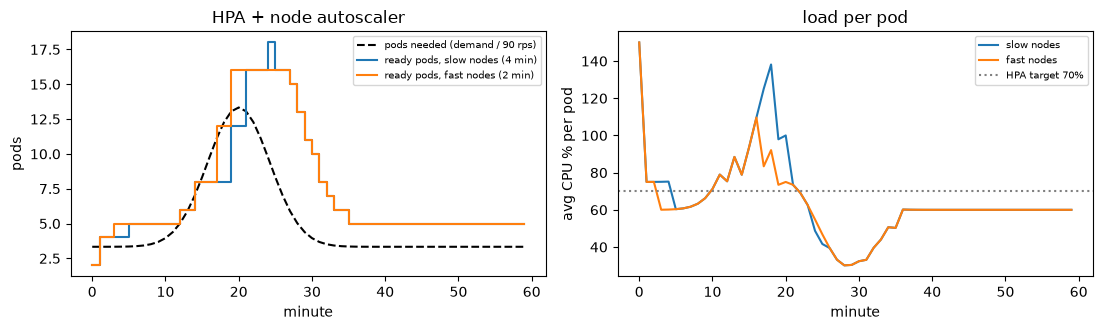

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(slow.minute, slow.demand_rps / 90, "k--", label="pods needed (demand / 90 rps)")
ax[0].step(slow.minute, slow.ready_pods, where="post", label="ready pods, slow nodes (4 min)")
ax[0].step(fast.minute, fast.ready_pods, where="post", label="ready pods, fast nodes (2 min)")
ax[0].set_xlabel("minute"); ax[0].set_ylabel("pods"); ax[0].set_title("HPA + node autoscaler"); ax[0].legend(fontsize=7)
ax[1].plot(slow.minute, slow.cpu_pct.clip(upper=200), label="slow nodes")
ax[1].plot(fast.minute, fast.cpu_pct.clip(upper=200), label="fast nodes")
ax[1].axhline(70, color="gray", ls=":", label="HPA target 70%")
ax[1].set_xlabel("minute"); ax[1].set_ylabel("avg CPU % per pod"); ax[1].set_title("load per pod"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What to notice.** The HPA reacts within a minute, but capacity arrives later because Pods and nodes need time to start. The scale-down stabilization keeps Pods around for a few minutes after the spike, which prevents flapping. The lesson for AI services: **startup time is part of your autoscaling design**. A GPU node can take several minutes to boot and a 30 GB model can take minutes more to load, so people keep a small warm buffer (`minReplicas`, over-provisioning "placeholder" Pods with low priority), and they scale on signals that move *before* users suffer (queue depth).

## 6. Scheduling

### 6.1 Requests, limits and QoS classes

**What it is.** A **request** is what the scheduler reserves for a container (used to decide *where* it fits). A **limit** is the maximum it may use at run time. CPU above the limit is **throttled** (slowed down). Memory above the limit gets the container **OOMKilled** (killed, exit code 137). Units: CPU in cores (`500m` = half a core), memory in bytes (`Mi`, `Gi`). GPUs are an **extended resource** (`nvidia.com/gpu: 1`): whole units only, and request must equal limit.

**Simple analogy.** A request is a reserved seat in a restaurant. A limit is the most food the kitchen will give you. A guest with no reservation (BestEffort) gets seated if there is space, but is asked to leave first when it gets crowded.

From requests and limits, Kubernetes gives each Pod a **QoS class**, which decides who is evicted first when a node runs out of memory:

| QoS class | Rule | Evicted |
|---|---|---|
| **Guaranteed** | every container has CPU and memory requests **equal** to limits | last |
| **Burstable** | at least one request or limit set, but not Guaranteed | middle |
| **BestEffort** | no requests or limits at all | first |

A common, safe pattern for model servers: set a memory request equal to the memory limit (no surprise OOM from neighbours), set a CPU request, and often no CPU limit (avoid throttling).

In [9]:
def qos_class(containers):
    """containers: list of dicts like {'requests': {'cpu': .., 'memory': ..}, 'limits': {...}}"""
    has_any = any(c.get("requests") or c.get("limits") for c in containers)
    if not has_any:
        return "BestEffort"
    guaranteed = all(
        all(r in c.get("limits", {}) for r in ("cpu", "memory")) and
        all(c.get("requests", c.get("limits", {})).get(r) == c["limits"][r] for r in ("cpu", "memory"))
        for c in containers)
    return "Guaranteed" if guaranteed else "Burstable"

examples = {
    "no resources at all":              [{}],
    "requests only":                    [{"requests": {"cpu": "500m", "memory": "1Gi"}}],
    "requests == limits":               [{"requests": {"cpu": "2", "memory": "8Gi"}, "limits": {"cpu": "2", "memory": "8Gi"}}],
    "limits only (requests copied)":    [{"limits": {"cpu": "1", "memory": "2Gi"}}],
    "memory req==lim, no CPU limit":    [{"requests": {"cpu": "1", "memory": "4Gi"}, "limits": {"memory": "4Gi"}}],
}
for name, cs in examples.items():
    print(f"{name:<34} -> {qos_class(cs)}")

no resources at all                -> BestEffort
requests only                      -> Burstable
requests == limits                 -> Guaranteed
limits only (requests copied)      -> Guaranteed
memory req==lim, no CPU limit      -> Burstable


### 6.2 Steering Pods: nodeSelector, affinity, taints and tolerations, topology spread

| Tool | Direction | Think of it as | Example |
|---|---|---|---|
| **nodeSelector** | Pod -> node | "only on nodes with this label" | `nvidia.com/gpu.product: NVIDIA-H100-80GB-HBM3` |
| **node affinity** | Pod -> node | nodeSelector with `In`/`NotIn`, required or just preferred | prefer spot nodes, require GPU nodes |
| **pod affinity** | Pod -> other Pods | "put me near Pods with label X" | cache next to the API (same node/zone) |
| **pod anti-affinity** | Pod -> other Pods | "keep me away from Pods with label X" | replicas of one model on different nodes |
| **taint** (on a node) | node repels Pods | "No entry unless you have a pass" | GPU nodes tainted so CPU-only Pods stay off |
| **toleration** (on a Pod) | Pod accepts a taint | the pass | GPU Pods tolerate `nvidia.com/gpu:NoSchedule` |
| **topologySpreadConstraints** | Pods across zones/nodes | "spread evenly, max skew 1" | replicas across 3 availability zones |

Taints keep the wrong Pods **off** a node; they do not pull the right Pods **onto** it. For GPU pools you usually need both: a taint on the GPU nodes and a nodeSelector or affinity on the GPU Pods.

```yaml
spec:
  nodeSelector: {nvidia.com/gpu.present: "true"}
  tolerations:
  - {key: nvidia.com/gpu, operator: Exists, effect: NoSchedule}
  affinity:
    podAntiAffinity:
      preferredDuringSchedulingIgnoredDuringExecution:
      - weight: 100
        podAffinityTerm:
          labelSelector: {matchLabels: {app: llm-server}}
          topologyKey: kubernetes.io/hostname       # prefer one replica per node
  topologySpreadConstraints:
  - {maxSkew: 1, topologyKey: topology.kubernetes.io/zone, whenUnsatisfiable: ScheduleAnyway,
     labelSelector: {matchLabels: {app: llm-server}}}
  priorityClassName: online-inference
  containers:
  - name: vllm
    resources:
      limits: {nvidia.com/gpu: 1}
```

### 6.3 Priority and preemption

**What it is.** A **PriorityClass** gives Pods a number. If a high-priority Pod cannot fit anywhere, the scheduler may **preempt** (evict) lower-priority Pods to make room. Typical setup: online inference high, batch training medium, research notebooks low, placeholder over-provisioning Pods lowest (they exist only to be preempted, which keeps warm spare capacity).

```yaml
apiVersion: scheduling.k8s.io/v1
kind: PriorityClass
metadata: {name: online-inference}
value: 100000
preemptionPolicy: PreemptLowerPriority
description: "User-facing model servers"
```

### 6.4 A runnable toy scheduler (with GPUs)

The real scheduler runs two phases for each Pod: **filter** (which nodes *can* take it: enough free CPU/memory/GPU, taints tolerated, selectors match) and **score** (which feasible node is *best*). Two classic scoring strategies:

- **LeastAllocated (spread):** prefer the emptiest node. Good for resilience.
- **MostAllocated (bin-pack):** prefer the fullest node that still fits. Good for cost and for GPUs, because it leaves whole nodes free for big jobs.

Our toy also does **preemption**: if a Pod fits nowhere, it looks for a node where evicting lower-priority Pods would make room.

In [10]:
NODES = {   # name: capacity and labels/taints
    "cpu-1": {"cpu": 16, "mem": 64,  "gpu": 0, "labels": {"pool": "cpu"}, "taints": []},
    "cpu-2": {"cpu": 16, "mem": 64,  "gpu": 0, "labels": {"pool": "cpu"}, "taints": []},
    "gpu-1": {"cpu": 32, "mem": 256, "gpu": 4, "labels": {"pool": "gpu"}, "taints": ["nvidia.com/gpu"]},
    "gpu-2": {"cpu": 32, "mem": 256, "gpu": 4, "labels": {"pool": "gpu"}, "taints": ["nvidia.com/gpu"]},
}
PODS = [  # name, cpu, mem(Gi), gpu, priority, nodeSelector, tolerations
    ("api-1",       2,  4, 0, 100, {}, []),
    ("api-2",       2,  4, 0, 100, {}, []),
    ("notebook-1",  4, 16, 1,  10, {"pool": "gpu"}, ["nvidia.com/gpu"]),
    ("notebook-2",  4, 16, 1,  10, {"pool": "gpu"}, ["nvidia.com/gpu"]),
    ("llm-7b-1",    8, 48, 1, 1000, {"pool": "gpu"}, ["nvidia.com/gpu"]),
    ("llm-7b-2",    8, 48, 1, 1000, {"pool": "gpu"}, ["nvidia.com/gpu"]),
    ("train-big",  16, 128, 4, 500, {"pool": "gpu"}, ["nvidia.com/gpu"]),   # needs a whole GPU node
    ("llm-70b",    16, 160, 4, 1000, {"pool": "gpu"}, ["nvidia.com/gpu"]),  # needs a whole GPU node too
    ("batch-etl",   6, 24, 0,  50, {}, []),
]

def schedule(pods, strategy):
    free = {n: {k: NODES[n][k] for k in ("cpu", "mem", "gpu")} for n in NODES}
    placed, log = {}, []                           # pod -> node
    spec = {p[0]: p for p in pods}

    def fits(p, n, extra=None):
        _, cpu, mem, gpu, _, sel, tol = p
        f = dict(free[n]) if extra is None else extra
        if any(NODES[n]["labels"].get(k) != v for k, v in sel.items()): return False   # nodeSelector
        if any(t not in tol for t in NODES[n]["taints"]): return False                 # taints
        return f["cpu"] >= cpu and f["mem"] >= mem and f["gpu"] >= gpu                 # resources

    def score(n):   # fraction of the node already used, averaged over resources it has
        used = [1 - free[n][k] / NODES[n][k] for k in ("cpu", "mem", "gpu") if NODES[n][k] > 0]
        u = sum(used) / len(used)
        return u if strategy == "MostAllocated" else -u

    def bind(p, n):
        for k, v in zip(("cpu", "mem", "gpu"), p[1:4]): free[n][k] -= v
        placed[p[0]] = n

    for p in pods:
        feasible = [n for n in NODES if fits(p, n)]
        if feasible:
            bind(p, max(feasible, key=score)); continue
        # preemption: find a node where evicting lower-priority pods makes room
        for n in NODES:
            victims = sorted([v for v, vn in placed.items() if vn == n and spec[v][4] < p[4]], key=lambda v: spec[v][4])
            trial, chosen = dict(free[n]), []
            for v in victims:
                if fits(p, n, trial): break
                for k, val in zip(("cpu", "mem", "gpu"), spec[v][1:4]): trial[k] += val
                chosen.append(v)
            if chosen and fits(p, n, trial):
                for v in chosen:
                    for k, val in zip(("cpu", "mem", "gpu"), spec[v][1:4]): free[n][k] += val
                    del placed[v]; log.append(f"preempted {v} (prio {spec[v][4]}) from {n} for {p[0]}")
                bind(p, n); break
        else:
            log.append(f"{p[0]}: Pending (0/{len(NODES)} nodes available)")
    return placed, log, free

for strategy in ["LeastAllocated", "MostAllocated"]:
    placed, log, free = schedule(PODS, strategy)
    print(f"=== {strategy} ===")
    by_node = defaultdict(list)
    for pod, node in placed.items(): by_node[node].append(pod)
    for n in NODES:
        print(f"  {n}: free gpu={free[n]['gpu']}/{NODES[n]['gpu']}  pods={by_node[n]}")
    for line in log: print("  !", line)

=== LeastAllocated ===
  cpu-1: free gpu=0/0  pods=['api-1', 'batch-etl']
  cpu-2: free gpu=0/0  pods=['api-2']
  gpu-1: free gpu=2/4  pods=['notebook-1', 'llm-7b-1']
  gpu-2: free gpu=2/4  pods=['notebook-2', 'llm-7b-2']
  ! train-big: Pending (0/4 nodes available)
  ! llm-70b: Pending (0/4 nodes available)
=== MostAllocated ===
  cpu-1: free gpu=0/0  pods=['api-1', 'api-2', 'batch-etl']
  cpu-2: free gpu=0/0  pods=[]
  gpu-1: free gpu=0/4  pods=['notebook-1', 'notebook-2', 'llm-7b-1', 'llm-7b-2']
  gpu-2: free gpu=0/4  pods=['llm-70b']
  ! preempted train-big (prio 500) from gpu-2 for llm-70b


**What to notice.**
- With **spread** scoring (LeastAllocated), the small GPU Pods land on both GPU nodes, so neither node has 4 free GPUs. Both 4-GPU Pods stay **Pending**, and preemption cannot help, because the Pods in the way (`llm-7b`) have high priority. This is **GPU fragmentation**: 4 GPUs are free in total, but not on one node.
- With **bin-pack** scoring (MostAllocated), small Pods fill `gpu-1` first and `gpu-2` stays whole. `train-big` gets it, and then the higher-priority `llm-70b` **preempts** `train-big` (in a real cluster the evicted Job Pod would be recreated and wait as Pending).
- Taints kept CPU-only Pods off the expensive GPU nodes, and bin-packing also emptied `cpu-2`, which a node autoscaler could now remove.

Real clusters use the scheduler's `NodeResourcesFit` plugin with the `MostAllocated` or `RequestedToCapacityRatio` strategy for GPU pools, and add-ons such as **Kueue** or **KAI Scheduler** for gang scheduling and GPU quotas (see the [GPU notebook](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb), which also simulates MIG slices).

## 7. Security

Kubernetes security has layers. Think of a building: **who may enter and which rooms they may open** (RBAC), **what people may carry inside** (Pod Security), **a guard at the door who checks every delivery** (admission control), and **where the deliveries come from** (image policy).

### 7.1 RBAC: Roles, ClusterRoles, bindings and ServiceAccounts

**What it is.** **RBAC** (Role-Based Access Control) decides whether a user or program may do a **verb** (`get`, `list`, `watch`, `create`, `update`, `patch`, `delete`) on a **resource** (`pods`, `secrets`, `deployments`) in a **namespace**.

- **Role**: a list of allowed rules inside one namespace.
- **ClusterRole**: the same, but cluster-wide or reusable in any namespace (also for non-namespaced things like nodes).
- **RoleBinding / ClusterRoleBinding**: gives a Role/ClusterRole to **subjects** (users, groups, ServiceAccounts).
- **ServiceAccount**: an identity for **Pods** (programs), not humans. Each Pod runs as one; its short-lived token lets it call the API. On clouds, a ServiceAccount can also be mapped to a cloud IAM role (EKS Pod Identity / IRSA, Azure Workload Identity, GKE Workload Identity Federation), so Pods get cloud permissions without stored keys.

RBAC is **allow-only** (no deny rules) and everything is denied by default. Grant the least you can; never give `cluster-admin` to an app.

```yaml
apiVersion: v1
kind: ServiceAccount
metadata: {name: model-deployer, namespace: chat}
---
apiVersion: rbac.authorization.k8s.io/v1
kind: Role
metadata: {name: deploy-models, namespace: chat}
rules:
- apiGroups: ["apps"]
  resources: ["deployments"]
  verbs: ["get", "list", "watch", "update", "patch"]
- apiGroups: [""]                 # "" = the core API group (pods, services, configmaps, secrets)
  resources: ["pods", "pods/log"]
  verbs: ["get", "list", "watch"]
---
apiVersion: rbac.authorization.k8s.io/v1
kind: RoleBinding
metadata: {name: deploy-models, namespace: chat}
subjects: [{kind: ServiceAccount, name: model-deployer, namespace: chat}]
roleRef: {apiGroup: rbac.authorization.k8s.io, kind: Role, name: deploy-models}
```

You can check permissions with `kubectl auth can-i patch deployments -n chat --as=system:serviceaccount:chat:model-deployer`. The toy below is a tiny version of that check.

In [11]:
roles = {
    ("chat", "deploy-models"): [({"apps"}, {"deployments"}, {"get", "list", "watch", "update", "patch"}),
                                ({""}, {"pods", "pods/log"}, {"get", "list", "watch"})],
    ("*", "view-nodes"):       [({""}, {"nodes"}, {"get", "list"})],          # a ClusterRole
}
bindings = [  # (namespace or '*' for ClusterRoleBinding, role key, subject)
    ("chat", ("chat", "deploy-models"), "system:serviceaccount:chat:model-deployer"),
    ("*",    ("*", "view-nodes"),       "group:sre"),
]
def can_i(subject, verb, group, resource, namespace, groups=()):
    who = {subject, *[f"group:{g}" for g in groups]}
    for b_ns, role_key, subj in bindings:
        if subj not in who or (b_ns != "*" and b_ns != namespace):
            continue
        for g, res, verbs in roles[role_key]:
            if group in g and resource in res and verb in verbs:
                return f"yes  (via binding to {role_key[1]})"
    return "no   (RBAC denies by default)"

sa = "system:serviceaccount:chat:model-deployer"
checks = [(sa, "patch", "apps", "deployments", "chat"),
          (sa, "delete", "apps", "deployments", "chat"),
          (sa, "get", "", "secrets", "chat"),
          (sa, "patch", "apps", "deployments", "search"),
          ("alice", "list", "", "nodes", None)]
for c in checks:
    print(f"can {c[0].split(':')[-1]:<15} {c[1]:<6} {c[3]:<12} in {str(c[4]):<7} -> {can_i(*c)}")
print(f"can alice (group sre) list nodes -> {can_i('alice', 'list', '', 'nodes', None, groups=['sre'])}")

can model-deployer  patch  deployments  in chat    -> yes  (via binding to deploy-models)
can model-deployer  delete deployments  in chat    -> no   (RBAC denies by default)
can model-deployer  get    secrets      in chat    -> no   (RBAC denies by default)
can model-deployer  patch  deployments  in search  -> no   (RBAC denies by default)
can alice           list   nodes        in None    -> no   (RBAC denies by default)
can alice (group sre) list nodes -> yes  (via binding to view-nodes)


### 7.2 Pod Security Standards and securityContext

**What it is.** The **Pod Security Standards** define three levels of how much a Pod may do on its node:

| Level | Meaning | Who uses it |
|---|---|---|
| **privileged** | no restrictions | system agents (CNI, GPU driver installer) only |
| **baseline** | blocks known privilege escalations (no privileged containers, no host networking/PID, no hostPath, ...) | most app namespaces, minimum |
| **restricted** | baseline plus hardening: run as non-root, drop all Linux capabilities, no privilege escalation, a seccomp profile | the goal for app namespaces |

The built-in **Pod Security Admission** controller enforces a level per namespace with labels (the old PodSecurityPolicy was removed in Kubernetes 1.25):

```yaml
apiVersion: v1
kind: Namespace
metadata:
  name: chat
  labels:
    pod-security.kubernetes.io/enforce: restricted   # reject violating Pods
    pod-security.kubernetes.io/warn: restricted      # warn the user
    pod-security.kubernetes.io/audit: restricted     # write to the audit log
```

A Pod that passes **restricted** sets a `securityContext` like this (the [containerizing notebook](../04_industry_containerizing_an_ml_service.ipynb) builds a non-root image for it):

```yaml
spec:
  securityContext:
    runAsNonRoot: true
    runAsUser: 10001
    seccompProfile: {type: RuntimeDefault}
  containers:
  - name: api
    securityContext:
      allowPrivilegeEscalation: false
      readOnlyRootFilesystem: true          # not required by "restricted", but good practice
      capabilities: {drop: ["ALL"]}
```

**For GPU Pods:** GPU access does not need `privileged: true`; the device plugin or DRA driver passes the device in. If a vendor chart asks for privileged mode for the *workload* (not the driver), ask why.

### 7.3 Admission control: ValidatingAdmissionPolicy, OPA Gatekeeper, Kyverno

**What it is.** An **admission controller** sees every create/update request *after* authentication and RBAC, and can **mutate** it (add defaults, inject a sidecar) or **validate** it (reject it). Custom rules plug in as **admission webhooks** or, with no webhook at all, as built-in **ValidatingAdmissionPolicy** objects written in **CEL** (Common Expression Language).

| Tool | How you write rules | Good at |
|---|---|---|
| **ValidatingAdmissionPolicy** (built in, GA since 1.30) | CEL expressions in YAML | simple checks with no extra component; **MutatingAdmissionPolicy** (GA in 1.36) does defaults/changes the same way |
| **OPA Gatekeeper** | Rego language in `ConstraintTemplate`s, applied with `Constraint`s | teams already using Open Policy Agent across systems; audits existing objects |
| **Kyverno** (CNCF graduated, March 2026) | YAML + CEL policy types: `ValidatingPolicy`, `MutatingPolicy`, `GeneratingPolicy`, `DeletingPolicy`, `ImageValidatingPolicy` | validate, **mutate**, **generate** and clean up resources, **verify image signatures**; the older `ClusterPolicy` kind is deprecated (Kyverno 1.19) and the `kyverno migrate` CLI converts it |

```yaml
# Built-in: reject Deployments whose containers use the :latest tag or no tag.
apiVersion: admissionregistration.k8s.io/v1
kind: ValidatingAdmissionPolicy
metadata: {name: no-latest-tag}
spec:
  failurePolicy: Fail
  matchConstraints:
    resourceRules:
    - {apiGroups: ["apps"], apiVersions: ["v1"], operations: ["CREATE", "UPDATE"], resources: ["deployments"]}
  validations:
  - expression: "object.spec.template.spec.containers.all(c, c.image.contains(':') && !c.image.endsWith(':latest'))"
    message: "pin an image tag or digest; ':latest' is not allowed"
---
apiVersion: admissionregistration.k8s.io/v1
kind: ValidatingAdmissionPolicyBinding
metadata: {name: no-latest-tag}
spec:
  policyName: no-latest-tag
  validationActions: [Deny]
```

```yaml
# Kyverno (new CEL-based policy types): only allow images from our registry ...
apiVersion: policies.kyverno.io/v1
kind: ValidatingPolicy
metadata: {name: trusted-registry}
spec:
  validationActions: [Deny]
  matchConstraints:
    resourceRules:
    - {apiGroups: [""], apiVersions: ["v1"], operations: ["CREATE", "UPDATE"], resources: ["pods"]}
  validations:
  - expression: "object.spec.containers.all(c, c.image.startsWith('registry.example.com/'))"
    message: "images must come from registry.example.com"
---
# ... and require a cosign signature on them (field names can shift between Kyverno releases; check the docs).
apiVersion: policies.kyverno.io/v1
kind: ImageValidatingPolicy
metadata: {name: signed-images}
spec:
  validationActions: [Deny]
  matchConstraints:
    resourceRules:
    - {apiGroups: [""], apiVersions: ["v1"], operations: ["CREATE"], resources: ["pods"]}
  matchImageReferences: [{glob: "registry.example.com/*"}]
  attestors:
  - name: cosign
    cosign: {key: {data: "-----BEGIN PUBLIC KEY----- ... -----END PUBLIC KEY-----"}}
  validations:
  - expression: "images.containers.map(image, verifyImageSignatures(image, [attestors.cosign])).all(e, e > 0)"
    message: "image signature verification failed"
```

### 7.4 Image policies (supply chain in one table)

| Control | Tool examples | What it stops |
|---|---|---|
| Pin images by tag **and digest** (`image@sha256:...`) | registry, Renovate | "same tag, different image" surprises |
| Scan images for known CVEs in CI and in the registry | Trivy, Grype, Docker Scout, cloud registry scanning | shipping known-vulnerable packages |
| Sign images and verify at admission | Sigstore **cosign**, Kyverno `ImageValidatingPolicy`, Sigstore policy-controller (`ClusterImagePolicy`), Notation | running images nobody in your org built |
| Allow-list registries | admission policy (above) | pulling random images from the internet |
| SBOMs and provenance attestations | Syft, BuildKit attestations, SLSA | not knowing what is inside an image |
| Sandboxed runtimes for untrusted code | `RuntimeClass` with gVisor or Kata Containers | a container escape from agent-generated code |

The toy below is a mini admission controller that checks a Pod spec against several of these rules, the way Gatekeeper or Kyverno would.

In [12]:
RULES = []
def rule(fn): RULES.append(fn); return fn

@rule
def trusted_registry(pod):
    bad = [c["image"] for c in pod["containers"] if not c["image"].startswith("registry.example.com/")]
    return f"untrusted registry: {bad}" if bad else None
@rule
def no_latest(pod):
    bad = [c["image"] for c in pod["containers"] if ":" not in c["image"].split("/")[-1] or c["image"].endswith(":latest")]
    return f"unpinned image tag: {bad}" if bad else None
@rule
def non_root(pod):
    return None if pod.get("securityContext", {}).get("runAsNonRoot") else "must set runAsNonRoot: true"
@rule
def memory_limit(pod):
    bad = [c["name"] for c in pod["containers"] if "memory" not in c.get("limits", {})]
    return f"containers without a memory limit: {bad}" if bad else None
@rule
def no_privileged(pod):
    bad = [c["name"] for c in pod["containers"] if c.get("privileged")]
    return f"privileged containers not allowed: {bad}" if bad else None

def admit(pod):
    problems = [msg for r in RULES if (msg := r(pod))]
    return ("ALLOWED", []) if not problems else ("DENIED", problems)

good = {"name": "chat-v2", "securityContext": {"runAsNonRoot": True},
        "containers": [{"name": "api", "image": "registry.example.com/chat:2.1.0", "limits": {"memory": "4Gi"}}]}
bad = {"name": "quick-test",
       "containers": [{"name": "api", "image": "someuser/llm-server:latest", "privileged": True},
                      {"name": "sidecar", "image": "registry.example.com/proxy"}]}
for pod in (good, bad):
    verdict, problems = admit(pod)
    print(f"{pod['name']}: {verdict}")
    for p in problems: print("   -", p)

chat-v2: ALLOWED
quick-test: DENIED
   - untrusted registry: ['someuser/llm-server:latest']
   - unpinned image tag: ['someuser/llm-server:latest', 'registry.example.com/proxy']
   - must set runAsNonRoot: true
   - containers without a memory limit: ['api', 'sidecar']
   - privileged containers not allowed: ['api']


## 8. Extensibility: CRDs, controllers and operators

**What it is.** A **CustomResourceDefinition (CRD)** teaches the API server a new object type, for example `InferenceService` (KServe), `RayCluster` (KubeRay), `NodePool` (Karpenter) or `ScaledObject` (KEDA). A **controller** is a program that watches objects and reconciles (section 1). An **operator** is a controller plus CRDs that encode a human operator's know-how for one application: "how to install, upgrade, back up and fail over a Postgres cluster", or "how to run a model server with autoscaling and canary rollout".

**Simple analogy.** A CRD adds a new form to the office ("Request a model deployment"). The operator is the clerk who reads every new form and does all the paperwork: books the rooms (Deployments), sets up the phones (Services), and keeps checking that everything stays as the form says.

**How you build one.**

| Tool | What it gives you |
|---|---|
| **Kubebuilder** (Kubernetes SIG project) | Go project scaffolding on top of **controller-runtime**: CRD types, reconcile loop, webhooks, tests |
| **Operator SDK** (Operator Framework) | builds on Kubebuilder for Go; also Helm-based and Ansible-based operators; integrates with **OLM** (Operator Lifecycle Manager) and OperatorHub |
| **kopf**, **Metacontroller** | write controllers in Python or with simple webhooks |

```yaml
apiVersion: apiextensions.k8s.io/v1
kind: CustomResourceDefinition
metadata: {name: modeldeployments.ml.example.com}
spec:
  group: ml.example.com
  scope: Namespaced
  names: {kind: ModelDeployment, plural: modeldeployments, singular: modeldeployment, shortNames: [md]}
  versions:
  - name: v1alpha1
    served: true
    storage: true
    subresources: {status: {}}
    schema:
      openAPIV3Schema:
        type: object
        properties:
          spec:
            type: object
            required: [model, replicas]
            properties:
              model:    {type: string}
              replicas: {type: integer, minimum: 0, maximum: 50}
              gpu:      {type: boolean}
---
apiVersion: ml.example.com/v1alpha1
kind: ModelDeployment
metadata: {name: support-bot, namespace: chat}
spec: {model: "qwen2.5-7b-instruct", replicas: 2, gpu: true}
```

Below is a toy operator for that `ModelDeployment`: it turns one high-level object into the low-level objects (Deployment + Service + PodDisruptionBudget), keeps them in sync, and writes back a status. Real operators do the same through the API server, with **owner references** so the children are garbage-collected when the parent is deleted.

In [13]:
api_objects = {}     # our fake API server storage: (kind, namespace, name) -> object

def render_children(md):
    ns, name, spec = md["namespace"], md["name"], md["spec"]
    owner = {"ownerReferences": [{"kind": "ModelDeployment", "name": name}]}
    res = {"limits": {"nvidia.com/gpu": 1}} if spec.get("gpu") else {"requests": {"cpu": "1"}}
    return {
        ("Deployment", ns, name): {"replicas": spec["replicas"], "image": f"registry.example.com/vllm-runtime:0.11 --model {spec['model']}", "resources": res, **owner},
        ("Service", ns, name): {"selector": {"app": name}, "port": 80, **owner},
        ("PodDisruptionBudget", ns, name): {"minAvailable": max(spec["replicas"] - 1, 0), **owner},
    }

def reconcile_model_deployment(md):
    changes = []
    for key, want in render_children(md).items():
        have = api_objects.get(key)
        if have != want:
            changes.append(("create" if have is None else "update") + f" {key[0]}/{key[2]}")
            api_objects[key] = want
    md["status"] = {"observedReplicas": md["spec"]["replicas"], "ready": True}
    return changes or ["no changes (already in sync)"]

md = {"namespace": "chat", "name": "support-bot", "spec": {"model": "qwen2.5-7b-instruct", "replicas": 2, "gpu": True}}
print("pass 1:", reconcile_model_deployment(md))
print("pass 2:", reconcile_model_deployment(md))
api_objects[("Deployment", "chat", "support-bot")]["replicas"] = 7      # someone hand-edits the child
print("pass 3 (drift fixed):", reconcile_model_deployment(md))
md["spec"]["replicas"] = 4                                              # user edits the parent
print("pass 4 (spec changed):", reconcile_model_deployment(md))
print("PDB now:", api_objects[("PodDisruptionBudget", "chat", "support-bot")])

pass 1: ['create Deployment/support-bot', 'create Service/support-bot', 'create PodDisruptionBudget/support-bot']
pass 2: ['no changes (already in sync)']
pass 3 (drift fixed): ['update Deployment/support-bot']
pass 4 (spec changed): ['update Deployment/support-bot', 'update PodDisruptionBudget/support-bot']
PDB now: {'minAvailable': 3, 'ownerReferences': [{'kind': 'ModelDeployment', 'name': 'support-bot'}]}


## 9. Packaging and delivery: Helm vs Kustomize

**What it is.** Real apps need many YAML files that differ a little between environments (dev uses 1 replica and a small GPU, prod uses 6 replicas and an H100). Two tools solve this differently:

- **Helm**: a package manager. A **chart** is a folder of **templates** with placeholders, plus a `values.yaml`; `helm install` renders them and tracks a **release** you can upgrade or roll back. Charts are shared through repositories and OCI registries. (Helm 4, released in November 2025, is the current major version: it uses server-side apply for new installs and has a new WebAssembly plugin system. Helm 3 charts keep working; Helm 3 itself only gets security fixes until February 2027.)
- **Kustomize**: no templates. You keep plain YAML as a **base** and write small **overlays** that patch it per environment. It is built into kubectl: `kubectl apply -k overlays/prod`.

**Simple analogy.** Helm is a mail-merge letter with blanks to fill in. Kustomize is a printed letter plus sticky notes that change a few words for each recipient.

| | Helm | Kustomize |
|---|---|---|
| Model | templates + values | base + patches (overlays) |
| Packaging and sharing | yes (charts, versions, dependencies) | no (just folders) |
| Release history / rollback | yes (`helm rollback`) | no (use Git history) |
| Logic (if/loops) | yes (Go templates), can become hard to read | deliberately none |
| Best for | installing third-party software (GPU Operator, KServe, Prometheus) and shipping your app to others | your own app's per-environment differences |

Many teams use both: Helm for vendor charts, Kustomize (sometimes on top of rendered Helm output) for their own apps, and a GitOps tool (Argo CD, Flux) to apply them. Progressive delivery (canary, blue-green) comes from **Argo Rollouts** or Flagger; multi-step ML pipelines from **Argo Workflows** or Kubeflow Pipelines. All of this is taught in [Helm and GitOps](../03_helm_and_gitops.ipynb) and [safe model rollout strategies](../../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb).

```yaml
# base/kustomization.yaml
resources: [deployment.yaml, service.yaml]
---
# overlays/prod/kustomization.yaml
resources: ["../../base"]
namespace: chat-prod
images:
- {name: registry.example.com/model-api, newTag: "1.4.2"}
patches:
- target: {kind: Deployment, name: model-api}
  patch: |-
    - op: replace
      path: /spec/replicas
      value: 6
```

The toy below shows what Kustomize does conceptually: start from a base and apply overlay patches, without any templating.

In [14]:
def deep_merge(base, patch):
    """Strategic-merge-like for dicts: patch values win, nested dicts merge, None deletes a key."""
    out = copy.deepcopy(base)
    for k, v in patch.items():
        if v is None:
            out.pop(k, None)
        elif isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = deep_merge(out[k], v)
        else:
            out[k] = copy.deepcopy(v)
    return out

base = {"kind": "Deployment", "metadata": {"name": "model-api"},
        "spec": {"replicas": 1, "template": {"image": "registry.example.com/model-api:dev",
                                             "resources": {"limits": {"memory": "2Gi"}}}}}
overlays = {
    "dev":  {"metadata": {"namespace": "chat-dev"}},
    "prod": {"metadata": {"namespace": "chat-prod"},
             "spec": {"replicas": 6, "template": {"image": "registry.example.com/model-api:1.4.2",
                                                  "resources": {"limits": {"memory": "8Gi", "nvidia.com/gpu": 1}}}}},
}
for env, patch in overlays.items():
    print(f"--- {env} ---")
    print(json.dumps(deep_merge(base, patch), indent=1))

--- dev ---
{
 "kind": "Deployment",
 "metadata": {
  "name": "model-api",
  "namespace": "chat-dev"
 },
 "spec": {
  "replicas": 1,
  "template": {
   "image": "registry.example.com/model-api:dev",
   "resources": {
    "limits": {
     "memory": "2Gi"
    }
   }
  }
 }
}
--- prod ---
{
 "kind": "Deployment",
 "metadata": {
  "name": "model-api",
  "namespace": "chat-prod"
 },
 "spec": {
  "replicas": 6,
  "template": {
   "image": "registry.example.com/model-api:1.4.2",
   "resources": {
    "limits": {
     "memory": "8Gi",
     "nvidia.com/gpu": 1
    }
   }
  }
 }
}


## 10. Health: probes, rolling updates and PodDisruptionBudgets

### 10.1 Probes

**What it is.** The kubelet runs **probes** against each container (an HTTP GET, a TCP connect, a gRPC health check, or a command):

| Probe | Question it answers | If it fails |
|---|---|---|
| **startupProbe** | "Has the app finished starting?" | keeps checking up to `failureThreshold x periodSeconds`, then restarts; other probes wait until it passes |
| **readinessProbe** | "Can it take traffic right now?" | Pod removed from Service endpoints (no restart) |
| **livenessProbe** | "Is it stuck and needs a restart?" | container restarted |

**Simple analogy.** Startup: "is the shop open yet?" Readiness: "is there a cashier at the till right now?" Liveness: "is the cashier asleep and needs waking up?"

**Why this matters for AI.** A model server may need minutes to load weights. With only a liveness probe, the kubelet kills it before it finishes loading, forever: a classic **CrashLoopBackOff**. A **startupProbe** with a long enough budget fixes this.

```yaml
containers:
- name: vllm
  startupProbe:                       # allow up to 60 x 10s = 10 minutes to load the model
    httpGet: {path: /health, port: 8000}
    periodSeconds: 10
    failureThreshold: 60
  readinessProbe:
    httpGet: {path: /health, port: 8000}
    periodSeconds: 5
  livenessProbe:                      # only starts after the startup probe passed
    httpGet: {path: /health, port: 8000}
    periodSeconds: 10
    failureThreshold: 3
  lifecycle:
    preStop: {exec: {command: ["sleep", "10"]}}   # let the load balancer stop sending traffic first
terminationGracePeriodSeconds: 60     # time to finish in-flight requests after SIGTERM
```

The toy simulates a model that takes 150 seconds to load, with and without a startup probe.

In [15]:
def run_pod(load_time_s, liveness_delay, liveness_period, liveness_fail, startup_budget=None, horizon=900):
    """Return a list of events. The container is healthy only after load_time_s since its last (re)start."""
    t, started, restarts, events, backoff = 0, 0, 0, [], 10
    startup_passed = startup_budget is None
    while t < horizon:
        up = t - started
        healthy = up >= load_time_s
        if not startup_passed:                              # startup probe phase
            if healthy:
                startup_passed = True; events.append(f"t={t:>3}s startup probe passed, liveness now active")
            elif up >= startup_budget:
                restarts += 1; events.append(f"t={t:>3}s startup budget exceeded -> restart #{restarts}")
                started = t + backoff; t = started; startup_passed = False; continue
        elif up >= liveness_delay and not healthy:          # liveness probe phase
            if up >= liveness_delay + liveness_period * liveness_fail:
                restarts += 1
                events.append(f"t={t:>3}s liveness failed {liveness_fail}x -> restart #{restarts}, back-off {backoff}s")
                started = t + backoff; t = started
                backoff = min(backoff * 2, 300)                 # CrashLoopBackOff: 10s, 20s, 40s ... capped at 5 min
                if startup_budget is not None: startup_passed = False
                continue
        if healthy and (not events or "Ready" not in events[-1]):
            events.append(f"t={t:>3}s model loaded, Pod Ready"); break
        t += 5
    return events, restarts

print("A) liveness only (initialDelay 30s, period 10s, 3 failures):")
ev, r = run_pod(150, 30, 10, 3)
for e in ev[:6]: print("   ", e)
print(f"    ... restarts in 15 min: {r}  (the model never finishes loading -> CrashLoopBackOff)")
print("\nB) startupProbe with a 10-minute budget, then the same liveness probe:")
ev, r = run_pod(150, 0, 10, 3, startup_budget=600)
for e in ev: print("   ", e)
print(f"    restarts: {r}")

A) liveness only (initialDelay 30s, period 10s, 3 failures):
    t= 60s liveness failed 3x -> restart #1, back-off 10s
    t=130s liveness failed 3x -> restart #2, back-off 20s
    t=210s liveness failed 3x -> restart #3, back-off 40s
    t=310s liveness failed 3x -> restart #4, back-off 80s
    t=450s liveness failed 3x -> restart #5, back-off 160s
    t=670s liveness failed 3x -> restart #6, back-off 300s
    ... restarts in 15 min: 6  (the model never finishes loading -> CrashLoopBackOff)

B) startupProbe with a 10-minute budget, then the same liveness probe:
    t=150s startup probe passed, liveness now active
    t=150s model loaded, Pod Ready
    restarts: 0


### 10.2 Rolling updates

**What it is.** When you change a Deployment's Pod template (new image), the Deployment creates a **new ReplicaSet** and shifts Pods over step by step. Two knobs control the pace:

- `maxSurge`: how many *extra* Pods may exist above `replicas` during the update.
- `maxUnavailable`: how many Pods may be *missing* (not ready) below `replicas`.

`maxSurge: 1, maxUnavailable: 0` is the safe default for model servers (capacity never drops), but needs spare room for one more Pod; with GPUs that may mean one spare GPU. `maxSurge: 0, maxUnavailable: 1` needs no spare GPU but runs one replica short during the update. Roll back with `kubectl rollout undo deployment/model-api`.

In [16]:
def rolling_update(replicas, max_surge, max_unavailable):
    """Step-by-step toy of the Deployment controller. Pods created in one step are Ready in the next."""
    old, new_ready, new_starting, step, rows = replicas, 0, 0, 0, []
    while old > 0 or new_ready < replicas:
        step += 1
        new_ready += new_starting; new_starting = 0                       # last step's new pods are Ready now
        # remove old pods only while Ready pods stay >= replicas - maxUnavailable
        remove = max(0, min(old, (old + new_ready) - (replicas - max_unavailable)))
        old -= remove
        # create new pods only while total pods stay <= replicas + maxSurge
        create = max(0, min(replicas + max_surge - (old + new_ready), replicas - new_ready))
        new_starting = create
        rows.append((step, old, new_ready, new_starting, old + new_ready + new_starting, old + new_ready))
    return pd.DataFrame(rows, columns=["step", "old", "new_ready", "new_starting", "total_pods", "ready_pods"])

print("replicas=4, maxSurge=1, maxUnavailable=0  (never below 4, needs room for 5)")
print(rolling_update(4, 1, 0).to_string(index=False))
print("\nreplicas=4, maxSurge=0, maxUnavailable=1  (never above 4, dips to 3)")
print(rolling_update(4, 0, 1).to_string(index=False))

replicas=4, maxSurge=1, maxUnavailable=0  (never below 4, needs room for 5)
 step  old  new_ready  new_starting  total_pods  ready_pods
    1    4          0             1           5           4
    2    3          1             1           5           4
    3    2          2             1           5           4
    4    1          3             1           5           4
    5    0          4             0           4           4

replicas=4, maxSurge=0, maxUnavailable=1  (never above 4, dips to 3)
 step  old  new_ready  new_starting  total_pods  ready_pods
    1    3          0             1           4           3
    2    2          1             1           4           3
    3    1          2             1           4           3
    4    0          3             1           4           3
    5    0          4             0           4           4


### 10.3 PodDisruptionBudgets

**What it is.** A **PodDisruptionBudget (PDB)** limits **voluntary** disruptions: node drains for upgrades, Karpenter consolidation, `kubectl drain`. It says "at least N Pods of this app must stay up" (`minAvailable`) or "at most N may be down at once" (`maxUnavailable`). It cannot prevent **involuntary** disruptions (a node crashing, a spot instance being reclaimed).

```yaml
apiVersion: policy/v1
kind: PodDisruptionBudget
metadata: {name: llm-server}
spec:
  minAvailable: 2                   # or maxUnavailable: 1
  selector: {matchLabels: {app: llm-server}}
```

A PDB of `minAvailable: 100%` (or equal to replicas) **blocks node drains forever**, which stalls cluster upgrades. The toy below shows the drain check the eviction API makes.

In [17]:
def try_drain(node, placement, pdb_min_available):
    """Evict pods on `node` one by one, respecting a PDB (minAvailable) per app."""
    healthy = Counter(app for app, n in placement)
    log = []
    for app, n in placement:
        if n != node: continue
        if healthy[app] - 1 >= pdb_min_available.get(app, 0):
            healthy[app] -= 1; log.append(f"evicted {app} from {node} (now {healthy[app]} up)")
        else:
            log.append(f"BLOCKED: evicting {app} would break its PDB (minAvailable={pdb_min_available[app]})")
    return log

placement = [("llm-server", "gpu-1"), ("llm-server", "gpu-1"), ("llm-server", "gpu-2"), ("embedder", "gpu-1")]
for pdb in ({"llm-server": 2, "embedder": 0}, {"llm-server": 3, "embedder": 0}):
    print(f"PDB {pdb}:")
    for line in try_drain("gpu-1", placement, pdb): print("   ", line)

PDB {'llm-server': 2, 'embedder': 0}:
    evicted llm-server from gpu-1 (now 2 up)
    BLOCKED: evicting llm-server would break its PDB (minAvailable=2)
    evicted embedder from gpu-1 (now 0 up)
PDB {'llm-server': 3, 'embedder': 0}:
    BLOCKED: evicting llm-server would break its PDB (minAvailable=3)
    BLOCKED: evicting llm-server would break its PDB (minAvailable=3)
    evicted embedder from gpu-1 (now 0 up)


## 11. Local clusters (how to try everything for real, for free)

| Tool | What it is | Good for |
|---|---|---|
| **kind** (Kubernetes IN Docker) | each "node" is a Docker container | fast, disposable, multi-node test clusters; CI; CKA practice |
| **minikube** | a single-node (or few-node) cluster in a VM or container, with add-ons (ingress, metrics-server, GPU support with some drivers) | learning, a dashboard, add-ons in one command |
| **k3s** | a lightweight, certified Kubernetes distribution in a single binary (from Rancher/SUSE) | edge devices, Raspberry Pi, small servers; **k3d** runs k3s inside Docker |
| **MicroK8s** | Canonical's snap-installed Kubernetes | Ubuntu machines, quick single-node |
| **kubeadm** | the official tool to bootstrap a real cluster on your own machines | learning how clusters are built; on-prem; it is what CKA tasks use |

**A 15-minute lab with kind** (run these in a terminal; they are not executed here):

```bash
# 1. create a 3-node cluster (1 control plane + 2 workers)
cat > kind.yaml <<'EOF'
kind: Cluster
apiVersion: kind.x-k8s.io/v1alpha4
nodes: [{role: control-plane}, {role: worker}, {role: worker}]
EOF
kind create cluster --name lab --config kind.yaml
kubectl get nodes

# 2. deploy, expose, scale, watch the reconcile loop heal
kubectl create deployment web --image=nginx:1.27 --replicas=3
kubectl expose deployment web --port=80
kubectl delete pod -l app=web --wait=false && kubectl get pods -w    # new pods appear
kubectl scale deployment web --replicas=5

# 3. taints and scheduling
kubectl taint nodes lab-worker2 dedicated=gpu:NoSchedule
kubectl get pods -o wide            # new pods avoid lab-worker2

# 4. troubleshooting practice: break it on purpose
kubectl set image deployment/web nginx=nginx:does-not-exist
kubectl get pods; kubectl describe pod <name> | tail -20     # ImagePullBackOff
kubectl rollout undo deployment/web

kind delete cluster --name lab
```

For GPU practice without a GPU, the open-source **fake GPU operator** (from Run:ai, now part of NVIDIA) makes nodes advertise fake `nvidia.com/gpu` resources, and **KWOK** simulates thousands of fake nodes for scheduler experiments. The guarded cell below only talks to a cluster if `kubectl` exists and a context is configured.

In [18]:
if not HAS_KUBECTL:
    print("skipped: needs kubectl and a cluster (for example `kind create cluster`)")
else:
    try:
        out = subprocess.run(["kubectl", "get", "nodes", "-o", "wide"], capture_output=True, text=True, timeout=10)
        print(out.stdout or out.stderr or "no output")
    except Exception as e:                       # no cluster, no context, timeout ...
        print("skipped: kubectl found but no reachable cluster ->", type(e).__name__)

skipped: needs kubectl and a cluster (for example `kind create cluster`)


## 12. Managed Kubernetes and distributions

**What it is.** In **managed Kubernetes** the cloud runs the control plane (API server, etcd, upgrades) and often the nodes too; you run workloads. **Distributions** package Kubernetes with extra tooling for running it yourself or across many places.

**Service map**

| Need | AWS | Azure | Google Cloud | Self-managed / other |
|---|---|---|---|---|
| Managed Kubernetes | **EKS** | **AKS** | **GKE** | OpenShift (ROSA on AWS, ARO on Azure), Rancher RKE2 |
| "Nodes managed for you" mode | EKS Auto Mode (Karpenter inside, immutable nodes replaced at most every 21 days), Fargate | AKS Automatic (Node Auto Provisioning = managed Karpenter, plus KEDA, VPA, Cilium networking) | GKE Autopilot (the default mode for new clusters) | - |
| Node autoscaling | Karpenter, Cluster Autoscaler | Cluster Autoscaler, NAP | GKE cluster autoscaler / node auto-provisioning | Cluster Autoscaler, Karpenter (some providers) |
| Container registry | ECR | ACR | Artifact Registry | Harbor, Quay |
| Pod -> cloud IAM identity | EKS Pod Identity, IRSA | Workload Identity (Entra ID) | Workload Identity Federation for GKE | SPIFFE/SPIRE |
| Gateway / L7 load balancing | AWS Load Balancer Controller, VPC Lattice (Gateway API) | Application Gateway for Containers; the AKS app routing add-on uses Gateway API from AKS 1.36 | GKE Gateway (and GKE Inference Gateway) | Envoy Gateway, Istio, Cilium |
| Cluster on your own hardware / edge | EKS Anywhere, EKS Hybrid Nodes | AKS enabled by Azure Arc | Google Distributed Cloud | kubeadm, k3s, OpenShift, Rancher |

| Distribution | One-line summary |
|---|---|
| **Red Hat OpenShift** (4.x line) | an enterprise Kubernetes platform with stricter security defaults, built-in registry, CI/CD, an operator catalogue (OperatorHub) and OpenShift AI for ML; runs on-prem and as managed services. |
| **Rancher** (SUSE) | a management plane for many clusters anywhere, with its own distributions RKE2 and k3s. |
| VMware vSphere Kubernetes Service, Mirantis, Canonical Kubernetes | other common enterprise options. |

**When to use which.** Use managed Kubernetes unless you have a reason not to (regulation, on-prem GPUs, air-gapped sites). Use the "nodes managed for you" mode for small teams. Use OpenShift or Rancher when you run many clusters across clouds and data centres and want one way to manage them.

## 13. Troubleshooting playbook

**The three commands that solve most problems:**

```bash
kubectl get pods -n chat -o wide                    # status, restarts, node
kubectl describe pod <pod> -n chat                  # the Events section at the bottom tells you WHY
kubectl logs <pod> -n chat --previous               # logs of the crashed (previous) container
kubectl get events -n chat --sort-by=.lastTimestamp
kubectl debug -it <pod> --image=busybox --target=api   # ephemeral debug container in a running Pod
kubectl top pods -n chat                            # live CPU/memory (needs metrics-server)
```

| Symptom | What it means | Usual causes | First fix |
|---|---|---|---|
| **Pending** | the scheduler cannot place the Pod | not enough CPU/memory/GPU; untolerated taint; nodeSelector matches no node; PVC not bound; quota exceeded | `describe` -> read the `FailedScheduling` message; add nodes, fix selectors/tolerations, lower requests |
| **ContainerCreating** (stuck) | node is setting it up | image still pulling (large CUDA images!), volume cannot attach, CNI problem, missing Secret/ConfigMap | `describe` events; check the PVC and referenced objects |
| **ImagePullBackOff / ErrImagePull** | the node cannot pull the image | typo in name or tag, private registry without `imagePullSecrets`, rate limit, wrong CPU architecture | check the image name, registry credentials, `docker pull` it yourself |
| **CrashLoopBackOff** | the container starts and exits again and again; kubelet waits longer each time (10s, 20s, 40s, ... up to 5 minutes by default; the cap is configurable per node since 1.35; the counter resets after 10 minutes of running fine) | app error, missing env var/config, liveness probe killing a slow-loading model, wrong command | `logs --previous`; add a startupProbe; check config |
| **OOMKilled** (exit code 137) | the container used more memory than its limit | limit too low, memory leak, a bigger batch or longer context than tested | raise the memory limit (and request), reduce batch size |
| **Running but 0/1 Ready** | readiness probe failing | app not listening on that port/path, dependency down | `describe` probe failures; `kubectl port-forward` and test |
| **Evicted** | kubelet removed it under node pressure | node out of disk or memory; BestEffort Pods go first | set requests, clean disk, add ephemeral-storage requests |
| **Service gives no response** | no endpoints | selector labels do not match the Pods, Pods not Ready, wrong `targetPort`, NetworkPolicy blocks | `kubectl get endpointslices -l kubernetes.io/service-name=<svc>` |
| GPU Pod Pending with `Insufficient nvidia.com/gpu` | no free GPU advertised | device plugin / GPU Operator not running, all GPUs in use, MIG profile mismatch | check the device plugin DaemonSet, `kubectl describe node` allocatable |

The toy below is a rule-based "diagnose from events" helper. It reads the kind of text `kubectl describe pod` prints and suggests the cause, exactly the reasoning you would do by hand (and a simple version of what AI troubleshooting assistants such as k8sgpt automate).

In [19]:
DIAGNOSIS_RULES = [  # (regex on status/events/last-state, diagnosis, suggested next step)
    (r"Insufficient nvidia\.com/gpu",      "no free GPU in the cluster",                 "check device plugin pods and node allocatable; add a GPU node or free one"),
    (r"untolerated taint",                 "node taint not tolerated",                   "add a toleration or schedule elsewhere"),
    (r"Insufficient (cpu|memory)",         "requests do not fit on any node",            "lower requests or add nodes (check the autoscaler)"),
    (r"didn't match Pod's node affinity|node\(s\) didn't match .*selector", "nodeSelector/affinity matches no node", "fix the labels or the selector"),
    (r"unbound immediate PersistentVolumeClaims|pod has unbound", "PVC not bound",               "check the StorageClass and the PVC events"),
    (r"exceeded quota",                    "namespace ResourceQuota exceeded",           "raise the quota or lower requests"),
    (r"OOMKilled|exit code 137",           "container exceeded its memory limit",        "raise memory limit/request or reduce batch size"),
    (r"(manifest unknown|not found).*image|Failed to pull image", "image name/tag wrong or not reachable", "fix the image reference; check the registry"),
    (r"unauthorized|authentication required|pull access denied", "registry credentials missing", "add imagePullSecrets or a node IAM role"),
    (r"no match for platform|exec format error", "image built for another CPU architecture", "build multi-arch images with docker buildx"),
    (r"Liveness probe failed",             "liveness probe is killing the container",    "add a startupProbe or a longer threshold"),
    (r"Readiness probe failed",            "app not ready (no traffic sent)",            "check the health endpoint and its dependencies"),
    (r"secret .* not found|configmap .* not found", "referenced Secret/ConfigMap missing",    "create it or fix the name"),
    (r"Back-off restarting failed container", "crash loop (look at the previous logs)",  "kubectl logs --previous"),
]
def diagnose(text):
    hits = [(d, s) for pat, d, s in DIAGNOSIS_RULES if re.search(pat, text, flags=re.I)]
    return hits or [("unknown", "read the full describe output and logs")]

cases = {
    "llm-70b-0 (Pending)": "Warning FailedScheduling 0/6 nodes are available: 2 Insufficient nvidia.com/gpu, 4 node(s) had untolerated taint {dedicated: infra}.",
    "embedder-7c9 (CrashLoopBackOff)": "Last State: Terminated Reason: OOMKilled Exit Code: 137\nWarning BackOff Back-off restarting failed container embed",
    "vllm-5d4 (CrashLoopBackOff)": "Warning Unhealthy Liveness probe failed: Get http://10.0.3.7:8000/health: connection refused\nWarning BackOff Back-off restarting failed container",
    "api-66f (ImagePullBackOff)": "Warning Failed Failed to pull image registry.example.com/model-api:1.4.3: manifest unknown",
    "worker-1 (Error)": "standard_init_linux.go: exec user process caused: exec format error",
}
for pod, text in cases.items():
    print(pod)
    for d, s in diagnose(text):
        print(f"   cause: {d:<42} next: {s}")

llm-70b-0 (Pending)
   cause: no free GPU in the cluster                 next: check device plugin pods and node allocatable; add a GPU node or free one
   cause: node taint not tolerated                   next: add a toleration or schedule elsewhere
embedder-7c9 (CrashLoopBackOff)
   cause: container exceeded its memory limit        next: raise memory limit/request or reduce batch size
   cause: crash loop (look at the previous logs)     next: kubectl logs --previous
vllm-5d4 (CrashLoopBackOff)
   cause: liveness probe is killing the container    next: add a startupProbe or a longer threshold
   cause: crash loop (look at the previous logs)     next: kubectl logs --previous
api-66f (ImagePullBackOff)
   cause: image name/tag wrong or not reachable      next: fix the image reference; check the registry
worker-1 (Error)
   cause: image built for another CPU architecture   next: build multi-arch images with docker buildx


## 14. Certification topic map (CNCF / Linux Foundation)

| Exam | Format | Domains and weights (official pages, late 2026; exams use Kubernetes 1.37) | Sections here |
|---|---|---|---|
| **KCNA** (Kubernetes and Cloud Native Associate) | multiple choice, 90 min | Kubernetes fundamentals 44%; container orchestration 28%; cloud native application delivery 16%; cloud native architecture 12% | 1, 2, 4, 5, 9, 12 |
| **CKAD** (Certified Kubernetes Application Developer) | hands-on in a live cluster, 2 h | application environment, configuration and security 25%; application design and build 20%; application deployment 20%; services and networking 20%; application observability and maintenance 15% | 2, 3, 4, 7.1-7.2, 9, 10, 13 |
| **CKA** (Certified Kubernetes Administrator) | hands-on, 2 h | **troubleshooting 30%**; cluster architecture, installation and configuration 25% (incl. Helm, Kustomize, CRDs/operators, CNI/CSI/CRI); services and networking 20% (incl. **Gateway API**, NetworkPolicies, CoreDNS); workloads and scheduling 15% (incl. autoscaling); storage 10% | 1-6, 8-13 |
| **CKS** (Certified Kubernetes Security Specialist; needs a passed CKA) | hands-on, 2 h | cluster setup 15%; cluster hardening 15%; system hardening 10%; minimize microservice vulnerabilities 20%; supply chain security 20%; monitoring, logging and runtime security 20% | 4.4, 7 |
| **KCSA** (Kubernetes and Cloud Native Security Associate) | multiple choice, 90 min | cluster component security 22%; security fundamentals 22%; threat model 16%; platform security 16%; overview of cloud native security 14%; compliance and frameworks 10% | 7 |
| **CKNE** (Certified Kubernetes Network Engineer, new in November 2026) | hands-on, 2 h | service networking and DNS 25%; network security and policy 25%; advanced traffic management 20%; core infrastructure and CNI 15%; observability 15% | 4 |
| **CNPA** (Cloud Native Platform Engineering Associate) | multiple choice | platform engineering fundamentals, observability/security, continuous delivery, platform APIs, developer portals, measuring platforms | 8, 9, 12 |

**AI-specific exams.** As of mid-November 2026 there is no AI-focused Kubernetes certification for people yet; CNCF has announced a **Kubernetes AI Associate (KAIA)** and a **Certified Kubernetes Inference Engineer (CKIE)** for 2027. The **Kubernetes AI Conformance** program certifies *platforms*, not people.

The GPU/AI topics (GPU Operator, DRA, Kueue, inference gateways, the **Kubernetes AI Conformance** program) are in the [GPU notebook](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb).

## 15. Recap: cheat sheet

| Topic | Remember this |
|---|---|
| Architecture | everything goes through the API server; etcd stores state; controllers reconcile desired vs actual; scheduler picks nodes; kubelet runs Pods |
| Workloads | Deployment (stateless), StatefulSet (identity + disk), DaemonSet (one per node), Job/CronJob (run to completion) |
| Config | ConfigMap for settings, Secret for credentials (base64 is not encryption; use KMS / external secrets) |
| Storage | PVC asks, StorageClass provisions via CSI, PV is the disk; mind access modes |
| Networking | Service = stable name for changing Pods; DNS `svc.ns.svc.cluster.local`; Gateway API replaces Ingress (community ingress-nginx retired 24 March 2026); NetworkPolicies need a CNI that enforces them |
| Scaling | HPA (Pods, formula with ratio), VPA (sizes), KEDA (events, to zero), Cluster Autoscaler / Karpenter (nodes); startup time matters |
| Scheduling | requests decide placement, limits cap usage; QoS Guaranteed/Burstable/BestEffort; taints repel, tolerations allow, affinity attracts; priority + preemption |
| Security | RBAC allow-only least privilege; Pod Security `restricted`; admission policies (VAP, Gatekeeper, Kyverno); signed, scanned, pinned images |
| Extensibility | CRD = new object type; operator = CRDs + controller with domain know-how (Kubebuilder, Operator SDK) |
| Delivery | Helm (templates, releases) vs Kustomize (base + overlays); GitOps applies them |
| Health | startupProbe for slow model loads; readiness gates traffic; liveness restarts; maxSurge/maxUnavailable; PDBs protect drains |
| Troubleshooting | `get` -> `describe` (Events) -> `logs --previous`; Pending = scheduling, CrashLoop = app/probe, ImagePull = image/registry, 137 = OOM |

## 16. Interview questions

1. **What happens, step by step, when you run `kubectl apply` on a Deployment?** The API server authenticates, authorizes (RBAC), runs admission, stores it in etcd; the Deployment controller makes a ReplicaSet; the ReplicaSet controller makes Pods; the scheduler binds them to nodes; each kubelet starts the containers through the runtime and reports status.
2. **Deployment vs StatefulSet?** Deployment Pods are interchangeable with random names and shared storage choices; StatefulSet Pods have stable names, stable DNS and their own PVC each, and start/stop in order. Use StatefulSets for databases and peers that need identity.
3. **A Pod is Pending. How do you debug it?** `kubectl describe pod` and read the `FailedScheduling` event: insufficient resources (including GPUs), taints, selectors/affinity, unbound PVC, or quota. Then fix the cause or add capacity.
4. **Liveness vs readiness vs startup probe?** Readiness removes the Pod from load balancing; liveness restarts it; startup protects slow starters (model loading) from liveness kills until they are up.
5. **Why is CPU utilisation a poor HPA metric for a GPU model server?** The bottleneck is the GPU and the request queue; CPU can be low while users wait. Scale on queue depth, in-flight requests or KV-cache usage (via a metrics adapter or KEDA).
6. **Cluster Autoscaler vs Karpenter?** CA scales pre-defined node groups up and down; Karpenter provisions right-sized instances directly from Pending Pods' needs and consolidates under-used nodes, usually faster and with less configuration of instance types.
7. **What are QoS classes and why do they matter?** Guaranteed (requests = limits), Burstable, BestEffort. Under memory pressure the kubelet evicts BestEffort first, then Burstable. Critical model servers should be Guaranteed for memory.
8. **Taints vs node affinity?** Taints on nodes repel Pods without a toleration; affinity on Pods attracts them to nodes. To dedicate GPU nodes you need both: taint the nodes, and select/tolerate in the GPU Pods.
9. **Is a Kubernetes Secret secure?** Only base64-encoded by default. Secure it with RBAC, encryption at rest (KMS), and preferably an external secret manager; avoid putting secrets in env vars that get logged.
10. **Why move from Ingress to Gateway API?** Ingress is feature-frozen and the popular community ingress-nginx controller is retired; Gateway API is role-oriented (GatewayClass/Gateway/Routes), portable across implementations, supports traffic splitting, header matching, gRPC and cross-namespace references, and is extended for LLM inference routing.
11. **What is an operator?** CRDs plus a controller that encodes operational knowledge for one app, reconciling a high-level custom resource into lower-level objects and handling upgrades, backups and failover.
12. **Helm or Kustomize?** Helm to package and install (especially third-party software, with releases and rollbacks); Kustomize for template-free per-environment overlays of your own YAML. Many teams use both, applied by GitOps.

## 17. Further reading

- Kubernetes documentation, concepts: https://kubernetes.io/docs/concepts/
- Kubernetes components: https://kubernetes.io/docs/concepts/overview/components/
- Workloads (Deployments, StatefulSets, DaemonSets, Jobs, CronJobs): https://kubernetes.io/docs/concepts/workloads/
- Scheduling, preemption and eviction: https://kubernetes.io/docs/concepts/scheduling-eviction/
- Pod QoS classes: https://kubernetes.io/docs/concepts/workloads/pods/pod-qos/
- Horizontal Pod Autoscaling (algorithm details): https://kubernetes.io/docs/tasks/run-application/horizontal-pod-autoscale/
- Probes: https://kubernetes.io/docs/tasks/configure-pod-container/configure-liveness-readiness-startup-probes/
- Pod Security Standards: https://kubernetes.io/docs/concepts/security/pod-security-standards/
- RBAC: https://kubernetes.io/docs/reference/access-authn-authz/rbac/
- ValidatingAdmissionPolicy: https://kubernetes.io/docs/reference/access-authn-authz/validating-admission-policy/
- Network policies: https://kubernetes.io/docs/concepts/services-networking/network-policies/
- Gateway API: https://gateway-api.sigs.k8s.io/
- Ingress NGINX retirement announcement: https://kubernetes.io/blog/2025/11/11/ingress-nginx-retirement/ and the Ingress page (API frozen): https://kubernetes.io/docs/concepts/services-networking/ingress/
- Kubernetes releases and version support: https://kubernetes.io/releases/ ; v1.37 release notes: https://kubernetes.io/blog/2026/08/26/kubernetes-v1-37-release/
- KEDA: https://keda.sh/docs/
- Karpenter: https://karpenter.sh/docs/
- Vertical Pod Autoscaler: https://kubernetes.io/docs/concepts/workloads/autoscaling/vertical-pod-autoscale/
- Gateway API releases: https://github.com/kubernetes-sigs/gateway-api/releases ; Helm 3 end of life: https://helm.sh/blog/helm-v3-end-of-life/
- Kyverno policy types: https://kyverno.io/docs/policy-types/ ; OPA Gatekeeper: https://open-policy-agent.github.io/gatekeeper/website/docs/
- Kubebuilder book: https://book.kubebuilder.io/ ; Operator SDK: https://sdk.operatorframework.io/
- Helm: https://helm.sh/docs/ ; Kustomize: https://kubectl.docs.kubernetes.io/references/kustomize/
- kind: https://kind.sigs.k8s.io/ ; minikube: https://minikube.sigs.k8s.io/ ; k3s: https://docs.k3s.io/
- CKA: https://training.linuxfoundation.org/certification/certified-kubernetes-administrator-cka/ ; CKAD, CKS, KCNA, KCSA and CKNE pages on the same site
- Book: *Kubernetes Up and Running* (Burns, Beda, Hightower, Evenson); *Kubernetes Patterns* (Ibryam, Huss)

Related notebooks in this repo: [Kubernetes overview](01_kubernetes.ipynb), [Helm and GitOps](../03_helm_and_gitops.ipynb), [GPU infrastructure and LLM serving on Kubernetes](03_gpu_infrastructure_and_llm_serving_on_kubernetes.ipynb), [Containerizing an ML service](../04_industry_containerizing_an_ml_service.ipynb), [Designing for 100 million users](../../22_ML_System_Design/12_designing_for_100_million_users.ipynb).